# Análisis Exploratorio de Datos: rendimiento agrícola con datos multifuente

## Índice

| Etapa | Contenido |
|---|---|
| 0 | Preparación del entorno: bibliotecas, conexión, estilo y agrupación de variables |
| 1 | Características del dataset: estructura, conjuntos y calidad de datos |
| 2 | Resumen estadístico: metodología, estadística descriptiva y variable objetivo |
| 3 | Área de la parcela (`AREA_HA`) |
| 4 | Valores atípicos y coherencia del calendario fenológico |
| 5 | Distribución de las predictoras: entrenamiento vs. predicción |
| 6 | Relación de los predictores con el rendimiento |
| 7 | Multicolinealidad entre predictores |
| 8 | Consistencia entre sensores (Planet vs. Sentinel-2) |
| 9 | Selección *greedy* de variables |
| 10 | Análisis de componentes principales (PCA) |
| 11 | Comparabilidad entre entrenamiento y predicción (*data shift*) |
| 12 | Línea base de importancia de variables (Random Forest) |
| 13 | Conclusiones y recomendaciones para el modelado |

> **[Texto]** Etiquetas usadas en el Notebook: **[Texto]** contexto, **[Metodología]** definición del método, **[Estadística]** resultados numéricos, **[Interpretación]** lectura de resultados, **[Nota]** aclaración, **[Decisión de modelado]** acción para el modelo, **[Bibliografía]** fuentes.

- - -

## Etapa 0. Preparación del entorno

### 0.1 Bibliotecas

> **[Texto]** Importación de las bibliotecas para manipulación de datos, visualización, estadística, aprendizaje automático y conexión con la base de datos.

In [1]:
# BIBLIOTECAS
# Bibliotecas para manipulación de datos
import pandas as pd
import numpy as np
# Bibliotecas para manejo de fechas
import re
# Silenciar advertencias
import warnings
warnings.filterwarnings("ignore")
# Bibliotecas para visualización
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
# Bibliotecas para estadística y análisis de datos
from scipy import stats
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
# Bibliotecas para conexión con Supabase
import ssl
from sqlalchemy import create_engine
from sqlalchemy.engine import URL
from sqlalchemy.pool import NullPool


- - -

## Conexión a la base de datos

### 0.2 Dataset (conexión a Supabase)

> **[Texto]** Carga de la tabla de parcelas desde Supabase mediante el *pooler* en modo transacción (puerto 6543).

In [2]:
# Parámetros de conexión a Supabase, leídos desde .env (nunca escribir credenciales aquí)
import os
from dotenv import load_dotenv
load_dotenv()
DB_USER = os.environ["DB_USER"]
DB_PASS = os.environ["DB_PASSWORD"]
DB_HOST = os.environ["DB_HOST"]
DB_PORT = int(os.getenv("DB_PORT", "5432"))
DB_NAME = os.getenv("DB_NAME", "postgres")

# Construcción limpia de la URL para evitar que corte el usuario en el punto
db_url = URL.create(
    drivername="postgresql+pg8000",
    username=DB_USER,
    password=DB_PASS,
    host=DB_HOST,
    port=DB_PORT,
    database=DB_NAME,
)

# Configuración SSL para el pooler
ssl_ctx = ssl.create_default_context()
ssl_ctx.check_hostname = False
ssl_ctx.verify_mode = ssl.CERT_NONE

engine = create_engine(
    db_url,
    connect_args={"ssl_context": ssl_ctx},
    poolclass=NullPool
)

print("Conectando a Supabase...")

# Dataset de entrenamiento
query_train = """
    SELECT *
    FROM public.matriz_caracteristicas
    WHERE conjunto = 'ENTRENAMIENTO'
    ORDER BY id_poligono;
"""
df_train = pd.read_sql(query_train, engine)
print(f"Set de Entrenamiento cargado: {df_train.shape} (filas, columnas)")

# Dataset de predicción
query_pred = """
    SELECT *
    FROM public.matriz_caracteristicas
    WHERE conjunto = 'PREDICCION'
    ORDER BY id_poligono;
"""
df_pred = pd.read_sql(query_pred, engine)
print(f"Set de Predicción cargado: {df_pred.shape} (filas, columnas)")

# DataFrame concatenado de entrenamiento y predicción
# Nota: el conjunto de predicción trae el objetivo vacío; se silencia el aviso de pandas al concatenar
with warnings.catch_warnings():
    warnings.simplefilter("ignore", FutureWarning)
    df = pd.concat([df_train, df_pred], ignore_index=True)

# Renombrar columnas y ordenar por ID_POLIGONO
df = df.rename(columns={"id_poligono": "ID_POLIGONO", "conjunto": "CONJUNTO",
                        "rendimiento_t_ha": "RENDIMIENTO_T_HA", "area_ha_geod": "AREA_HA"})
# Convertir el objetivo a float, ya que PostgreSQL lo entrega como object.
df["RENDIMIENTO_T_HA"] = df["RENDIMIENTO_T_HA"].astype(float)
df = df.sort_values("ID_POLIGONO", ignore_index=True)
print(f"Dataset completo: {df.shape} (filas, columnas)")

Conectando a Supabase...
Set de Entrenamiento cargado: (138, 98) (filas, columnas)
Set de Predicción cargado: (59, 98) (filas, columnas)
Dataset completo: (197, 98) (filas, columnas)


- - -

## Configuración de visualización

### 0.3 Estilo común de las gráficas

> **[Texto]** Paleta categórica de orden fijo, paleta divergente azul-gris-naranja y opciones de visualización de pandas.

In [3]:
# Estilo común para todas las gráficas
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# Paleta: categórica en orden fijo + divergente azul-gris-naranja
AZUL, NARANJA, AQUA, AMARILLO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
MORADO, ROSA, GRIS_CAT = "#7b5cd6", "#d6457f", "#8a8984"
GRIS_TXT, GRIS_EJE = "#52514e", "#898781"
COLOR_CONJ = {"ENTRENAMIENTO": AZUL, "PREDICCION": NARANJA}
COLOR_FAM = {"Fenología Planet": AZUL, "Fenología Sentinel-2": NARANJA, "Agroclima": AQUA, "ERA5-Land": AMARILLO,
             "Suelo": MORADO, "Topografía": ROSA, "Parcela": GRIS_CAT}
CMAP_DIV = mcolors.LinearSegmentedColormap.from_list("div", [AZUL, "#f0efec", NARANJA])

# Configuración de estilo de las gráficas
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRIS_EJE, "axes.labelcolor": GRIS_TXT,
    "xtick.color": GRIS_EJE, "ytick.color": GRIS_EJE,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
    "axes.titleweight": "bold", "axes.titlesize": 11, "font.size": 9,
})

- - -

## Agrupación de variables

### 0.4 Clasificación de las columnas de la tabla

> **[Texto]** Las columnas del dataset se dividen en los siguientes grupos.

| Grupo | Variables | Uso |
|---|---|---|
| **Metadatos** | `ID_POLIGONO`, `municipio`, `estado`, `CONJUNTO`, `clima_pixel_id` | Identificación de la parcela |
| **Objetivo** | `RENDIMIENTO_T_HA` | Variable a predecir |
| **Diagnóstico** | `diag_*`, `topo_cobertura_pix`, `pend_cobertura_pix`, `ratio_cobertura_area`, `ratio_cobertura_pend`, `z_pixel_clima_m`, `pl_hueco_max_critico` | Analizar errores y decidir pesos |
| **Podadas** | `pl_ndvi_max_abr_oct`, `pl_ndvi_media_abr_oct`, `elev_min_m`, `elev_max_m`, `s2_eos50_doy`, `ac_lluvia_flor_mm`, `pl_duracion_dias`, `ac_eto_ciclo_mm`, `era5_dias_tmax28_flor`, `era5_dias_tmax28_llen`, `era5_dias_tmax30_flor`, `era5_dias_tmax30_llen` | Trazabilidad |
| **ETL** | `etl_*` | Identificadores de base creados por Supabase; se eliminan |
| **Predictoras** | 62 variables (detalle abajo) | Entrada del modelo |

> **[Estadística]** Variables predictoras por familia (62 variables en total).
>
> | Familia | Prefijo / variables | Descripción | N.º de variables |
> |---|---|---|---|
> | Parcela | `AREA_HA` | Área geodésica del polígono | 1 |
> | Topografía | `elev_media_m`, `elev_std_m`, `pend_media_grados`, `pend_p90_grados`, `pend_max_grados`, `dz_pixel_m` | Elevación y pendiente | 6 |
> | Fenología Planet | `pl_*` | Curva NDVI/LAI: inicio, pico, fin e integral del ciclo | 17 |
> | Fenología Sentinel-2 | `s2_*` | Fenología derivada de Sentinel-2 | 6 |
> | Agroclima | `ac_*` | Lluvia, días de lluvia, rachas secas, GDD, ETo y balance hídrico por etapa | 15 |
> | ERA5 | `era5_*` | Temperatura, VPD, humedad del suelo y radiación | 10 |
> | Suelo | `soil_*` | Textura, carbono orgánico, densidad, pH y agua disponible | 7 |

In [4]:
# Variable objetivo 
TARGET = "RENDIMIENTO_T_HA"

# Variables de metadatos (5 identificadores)
METADATOS = ["ID_POLIGONO", "municipio", "estado", "CONJUNTO", "clima_pixel_id"]

# Variables de diagnóstico (15 banderas)
variables_extra = [
    "topo_cobertura_pix",
    "pend_cobertura_pix",
    "ratio_cobertura_area",
    "ratio_cobertura_pend",
    "z_pixel_clima_m",
    "pl_hueco_max_critico",
]
diagnosticos = [
    c
    for c in df.columns
    if c.startswith("diag_") or c in variables_extra
]

# Variables podadas (12 banderas)
PODADAS = [
    "pl_ndvi_max_abr_oct",
    "pl_ndvi_media_abr_oct", 
    "elev_min_m",
    "elev_max_m",
    "s2_eos50_doy",
    "ac_lluvia_flor_mm",
    "pl_duracion_dias",
    "ac_eto_ciclo_mm",
    "era5_dias_tmax28_flor",
    "era5_dias_tmax28_llen",
    "era5_dias_tmax30_flor",
    "era5_dias_tmax30_llen",
]

# Variables de transformación ETL (3 por defecto de supabase)
etl = [c for c in df.columns if c.startswith("etl_")]

# Variables predictoras (62 features)
predictoras = [c for c in df.select_dtypes("number").columns
               if c not in METADATOS + diagnosticos + PODADAS + etl + [TARGET]]

# Función para clasificar la familia de las variables predictoras a partir de su prefijo
def familia_de(col):
    if col == "AREA_HA":
        return "Parcela"
    if col.startswith("pl_"):
        return "Fenología Planet"
    if col.startswith("s2_"):
        return "Fenología Sentinel-2"
    if col.startswith("ac_"):
        return "Agroclima"
    if col.startswith("era5_"):
        return "ERA5-Land"
    if col.startswith("soil_"):
        return "Suelo"
    return "Topografía"

# Se crea un DataFrame con la familia de cada variable predictora
meta = pd.DataFrame({"variable": predictoras, "familia": [familia_de(c) for c in predictoras]})
print(f"Predictoras numéricas: {len(predictoras)} | Banderas de diagnóstico: {len(diagnosticos)} | Banderas podadas: {len(PODADAS)} | Columnas ETL: {len(etl)}\n")
print(meta.groupby("familia")["variable"].agg(["count", lambda s: ", ".join(s)[:110]])
          .rename(columns={"count": "n_variables", "<lambda_0>": "variables"}))

Predictoras numéricas: 62 | Banderas de diagnóstico: 15 | Banderas podadas: 12 | Columnas ETL: 3

                      n_variables                                          variables
familia                                                                             
Agroclima                      15  ac_lluvia_pre_mm, ac_lluvia_veg_mm, ac_lluvia_...
ERA5-Land                      10  era5_tmax_media_flor_c, era5_vpd_medio_flor_kp...
Fenología Planet               17  pl_n_picos, pl_sos20_doy, pl_sos50_doy, pl_cen...
Fenología Sentinel-2            6  s2_n_picos, s2_sos50_doy, s2_centro_pico_doy, ...
Parcela                         1                                            AREA_HA
Suelo                           7  soil_arcilla_pct, soil_arena_pct, soil_soc_g_k...
Topografía                      6  elev_media_m, elev_std_m, pend_media_grados, p...


- - -

# Análisis Exploratorio de Datos (EDA)

> **[Texto]** El **Análisis Exploratorio de Datos** (EDA, por sus siglas en inglés: *Exploratory Data Analysis*) es la fase inicial del análisis estadístico y de la ciencia de datos. Consiste en examinar, resumir y visualizar un conjunto de datos antes de aplicar modelos estadísticos o de aprendizaje automático formales.
>
> Su objetivo principal es comprender la estructura subyacente de los datos, detectar patrones o anomalías (valores atípicos), comprobar supuestos y descubrir relaciones entre variables sin asumir hipótesis preconcebidas.

**Componentes clave del EDA**

| Componente | Descripción |
|---|---|
| **Resumen estadístico** | Medidas de tendencia central (media, mediana, moda) y de dispersión (desviación estándar, rango intercuartílico); pruebas de hipótesis. |
| **Visualización de datos** | Histogramas, diagramas de caja (*boxplots*), gráficos de dispersión (*scatter plots*) y mapas de calor (*heatmaps*). |
| **Tratamiento de anomalías** | Identificación y decisión sobre el manejo de valores faltantes (*missing values*) y valores atípicos (*outliers*). |
| **Análisis de relaciones** | Evaluación de correlaciones y dependencias entre múltiples variables. |

- - -

## 1. Características del dataset

In [5]:
# Filas y columnas del DataFrame
df.shape  

(197, 98)

In [6]:
# Primeras filas del DataFrame
print(df.head(5))  

  ID_POLIGONO     municipio    estado       CONJUNTO    AREA_HA  RENDIMIENTO_T_HA diag_y_redondo  diag_y_resolucion  elev_media_m  elev_std_m  elev_min_m  \
0     AGC_001   Calpulalpan  Tlaxcala  ENTRENAMIENTO   7.614999              3.50           True               0.50   2708.937487    5.658342      2697.0   
1     AGC_002  Chignahuapan    Puebla  ENTRENAMIENTO   2.309197              4.63          False               0.01   2611.461295    1.030804      2610.0   
2     AGC_003   Singuilucan   Hidalgo     PREDICCION  18.681726               NaN           None                NaN   2642.600950    3.719330      2635.0   
3     AGC_004   Calpulalpan  Tlaxcala  ENTRENAMIENTO   8.000470              3.00           True               0.50   2564.199598    3.916021      2557.0   
4     AGC_005  Chignahuapan    Puebla  ENTRENAMIENTO   2.272741              5.16          False               0.01   2623.981209    1.121331      2622.0   

   elev_max_m  topo_cobertura_pix  pend_media_grados  pen

In [7]:
# Información del DataFrame
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 197 entries, 0 to 196
Data columns (total 98 columns):
 #   Column                      Non-Null Count  Dtype              
---  ------                      --------------  -----              
 0   ID_POLIGONO                 197 non-null    object             
 1   municipio                   197 non-null    object             
 2   estado                      197 non-null    object             
 3   CONJUNTO                    197 non-null    object             
 4   AREA_HA                     197 non-null    float64            
 5   RENDIMIENTO_T_HA            138 non-null    float64            
 6   diag_y_redondo              138 non-null    object             
 7   diag_y_resolucion           138 non-null    float64            
 8   elev_media_m                197 non-null    float64            
 9   elev_std_m                  197 non-null    float64            
 10  elev_min_m                  197 non-null    float64           

### 1.1 Estructura del dataset: conjuntos de entrenamiento y predicción

In [8]:
# Conteo de registros por conjunto
conteo = df["CONJUNTO"].value_counts()
print(conteo, "\n")
print(f"Proporción entrenamiento / predicción: {conteo['ENTRENAMIENTO']/len(df):.1%} / {conteo['PREDICCION']/len(df):.1%}")

# Separación de los conjuntos de entrenamiento y predicción
train = df[df["CONJUNTO"] == "ENTRENAMIENTO"].copy()
pred = df[df["CONJUNTO"] == "PREDICCION"].copy()
y = train[TARGET]

print("\nTipos de datos:")
print(df.dtypes.value_counts())
# Variables numéricas y categóricas
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()
bolean_cols = df.select_dtypes(include=[bool]).columns.tolist()
print(f"Variables numéricas: {numeric_cols}")
print(f"Variables categóricas: {categorical_cols}")
print(f"Variables booleanas: {bolean_cols}")

# Distribución geográfica de las parcelas
print("\nParcelas por municipio y conjunto:")
print(pd.crosstab([df["estado"], df["municipio"]], df["CONJUNTO"], margins=True))

CONJUNTO
ENTRENAMIENTO    138
PREDICCION        59
Name: count, dtype: int64 

Proporción entrenamiento / predicción: 70.1% / 29.9%

Tipos de datos:
float64                62
int64                  20
object                  8
bool                    7
datetime64[ns, UTC]     1
Name: count, dtype: int64
Variables numéricas: ['AREA_HA', 'RENDIMIENTO_T_HA', 'diag_y_resolucion', 'elev_media_m', 'elev_std_m', 'elev_min_m', 'elev_max_m', 'topo_cobertura_pix', 'pend_media_grados', 'pend_p90_grados', 'pend_max_grados', 'pend_cobertura_pix', 'ratio_cobertura_area', 'ratio_cobertura_pend', 'z_pixel_clima_m', 'dz_pixel_m', 'pl_n_picos', 'pl_sos20_doy', 'pl_sos50_doy', 'pl_centro_pico_doy', 'pl_eos50_doy', 'pl_eos20_doy', 'pl_duracion_dias', 'pl_dias_meseta', 'pl_caida_intra_ciclo', 'pl_ndvi_pico', 'pl_ndvi_base', 'pl_amplitud', 'pl_integral_ciclo', 'pl_tasa_subida', 'pl_tasa_bajada', 'pl_hueco_max_critico', 'pl_ndvi_max_abr_oct', 'pl_ndvi_int_abr_oct', 'pl_ndvi_media_abr_oct', 'pl_lai_max_ciclo'

### 1.2 Calidad de datos: valores faltantes, duplicados y variables constantes

In [9]:
# Análisis de valores faltantes
faltantes = df.isna().sum()
faltantes = faltantes[faltantes > 0].to_frame("n_faltantes")
faltantes["%"] = (faltantes["n_faltantes"] / len(df) * 100).round(2)
print("Columnas con valores faltantes:")
print(faltantes, "\n")

# Los faltantes del objetivo deben coincidir exactamente con el conjunto de predicción
print("Faltantes de RENDIMIENTO por conjunto:")
print(df.groupby("CONJUNTO")[TARGET].apply(lambda s: s.isna().sum()), "\n")

print("Filas duplicadas:", df.drop(columns=etl).duplicated().sum())
print("ID_POLIGONO duplicados:", df["ID_POLIGONO"].duplicated().sum())
print("Corridas de ETL en la tabla:", df["etl_run_id"].nunique())

# Análisis de variables constantes
desv = df[predictoras].std()
constantes = list(desv[desv < 1e-8].index)
print("\nVariables constantes (std≈0):", constantes)

# Análisis de variables con un valor dominante
dominante = df[predictoras].apply(lambda s: s.value_counts(normalize=True).iloc[0])
print("Variables con un valor en > 90 % de las filas:", list(dominante[(dominante > 0.9) & (desv >= 1e-8)].index))

# Análisis de valores infinitos
infinitos = np.isinf(df[predictoras]).sum().sum()
print("Valores infinitos:", infinitos)

# Las variables constantes no aportan información: se excluyen del resto del análisis
predictoras = [c for c in predictoras if c not in constantes]
print(f"\nPredictoras tras eliminar constantes: {len(predictoras)}")

Columnas con valores faltantes:
                   n_faltantes      %
RENDIMIENTO_T_HA            59  29.95
diag_y_redondo              59  29.95
diag_y_resolucion           59  29.95 

Faltantes de RENDIMIENTO por conjunto:
CONJUNTO
ENTRENAMIENTO     0
PREDICCION       59
Name: RENDIMIENTO_T_HA, dtype: int64 



Filas duplicadas: 0
ID_POLIGONO duplicados: 0
Corridas de ETL en la tabla: 1

Variables constantes (std≈0): []
Variables con un valor en > 90 % de las filas: ['pl_n_picos', 's2_n_picos']
Valores infinitos: 0

Predictoras tras eliminar constantes: 62


> **[Nota]** Las variables `pl_n_picos` y `s2_n_picos` reportan datos similares. Se consideran para tratamiento; se conserva la que presente mejores métricas (ver 1.2.1).

#### 1.2.1 Comparación entre `pl_n_picos` y `s2_n_picos`

> **[Texto]** Estadísticas descriptivas de ambas variables y correlación de Spearman entre ellas, para decidir cuál conservar.

In [37]:
# Estadísticas descriptivas de las variables pl_n_picos y s2_n_picos (Se elige la que mejores métricas tenga)
print(df[["pl_n_picos", "s2_n_picos"]].describe().round(2))

       pl_n_picos  s2_n_picos
count       197.0      197.00
mean          1.1        1.04
std           0.3        0.19
min           1.0        1.00
25%           1.0        1.00
50%           1.0        1.00
75%           1.0        1.00
max           2.0        2.00


In [38]:
# Correlación de Spearman entre pl_n_picos y s2_n_picos
corr_picos, p_value_picos = spearmanr(df["pl_n_picos"], df["s2_n_picos"])
print(f"Correlación de Spearman entre pl_n_picos y s2_n_picos: {corr_picos:.3f}, p-value: {p_value_picos:.4f}")

Correlación de Spearman entre pl_n_picos y s2_n_picos: 0.587, p-value: 0.0000


#### [Interpretación]

- Ambas variables son casi constantes: más del 90 % de las parcelas tiene un solo pico (media de 1.10 en `pl_n_picos` y de 1.04 en `s2_n_picos`; máximo de 2 en las dos).
- La correlación de Spearman entre ellas es moderada ($\rho = 0.587$, $p < 0.0001$), por lo que no son redundantes entre sí.
- `pl_n_picos` tiene mayor variabilidad (desviación estándar de 0.30 frente a 0.19), es decir, distingue más parcelas con doble pico.

> **[Decisión de modelado]** Se conserva `pl_n_picos` y se descarta `s2_n_picos`, por ser la que aporta más variabilidad. Es consistente con la lista de columnas del apartado de recomendaciones, donde solo aparece `pl_n_picos`.

- - -

## 2. Resumen estadístico

### 2.1 Metodología

> **[Texto]** Esta sección reúne los métodos estadísticos y de aprendizaje automático utilizados a lo largo del Notebook. Cada método se identifica con su propósito, su regla de decisión o interpretación y la etapa del análisis donde se aplica.

**Criterio general de significancia**

> **[Metodología]** Para la contrastación de las hipótesis se adoptó un nivel de significancia de $\alpha = 0.05$, siguiendo la convención clásica de Fisher (1925) y el marco de decisión de Neyman y Pearson (1933). Este umbral equilibra el riesgo de cometer un Error Tipo I con la conservación de una potencia estadística adecuada ($1 - \beta \ge 0.80$), en línea con los lineamientos de Cohen (1988, 1992). Asimismo, siguiendo las recomendaciones de la American Statistical Association (Wasserstein & Lazar, 2016), los valores *p* se interpretaron de manera conjunta con la estimación de los tamaños del efecto correspondientes.

- - -

#### A. Medidas descriptivas y detección de valores atípicos

**Coeficiente de variación (CV)**

> **[Metodología]** El coeficiente de variación indica qué tan dispersos están los datos en relación con su media aritmética (Sanjuán, 2017). Se calcula como $CV = \sigma / |\mu|$. Un CV muy grande implica que la media es poco representativa del conjunto de datos.
>
> **[Aplicación]** Sección 2.2 (estadística descriptiva de predictoras y objetivo).

**Asimetría (*skewness*)**

> **[Metodología]** Mide el grado de simetría de la distribución de una variable respecto a su media.
>
> - Asimetría = 0: distribución simétrica.
> - Asimetría > 0: cola alargada hacia la derecha (la mayoría de los valores son pequeños y unos pocos son muy altos).
> - Asimetría < 0: cola alargada hacia la izquierda.
> - Criterio de lectura utilizado en el Notebook: valores entre $-0.5$ y $0.5$ se consideran un sesgo bajo; valores con $|\text{asimetría}| > 1$ se toman como candidatos a transformación (logaritmo, Box-Cox o raíz cuadrada) en modelos sensibles a la forma de la distribución.
>
> **[Aplicación]** Secciones 2.2, 2.3 y 3.

**Curtosis**

> **[Metodología]** Mide qué tan concentrados están los datos alrededor de la media y qué tan pesadas son las colas de la distribución. Se reporta como exceso de curtosis (Fisher), de modo que la distribución normal vale 0.
>
> - Curtosis > 0 (leptocúrtica): picos más agudos y colas más pesadas, con mayor presencia de valores extremos.
> - Curtosis < 0 (platicúrtica): curva más plana y colas más delgadas.
>
> **[Aplicación]** Secciones 2.2 y 2.3.

**Regla del rango intercuartílico (IQR)**

> **[Metodología]** Un valor se considera atípico cuando se encuentra por debajo de $Q_1 - 1.5 \cdot IQR$ o por encima de $Q_3 + 1.5 \cdot IQR$, donde $IQR = Q_3 - Q_1$ (Tukey, 1977). Es la misma regla que dibujan los bigotes del diagrama de caja (*boxplot*).
>
> **[Aplicación]** Secciones 2.3 y 4.

- - -

#### B. Normalidad y estructura de la distribución

**Prueba de Shapiro-Wilk**

> **[Metodología]** Se utiliza para comprobar si un conjunto de datos proviene de una población con distribución normal.
>
> - Hipótesis nula ($H_0$): los datos provienen de una distribución normal.
> - Hipótesis alternativa ($H_1$): los datos no provienen de una distribución normal.
> - Estadístico $W$: toma valores de 0 a 1. Un valor cercano a 1 indica que los datos se parecen a una distribución normal; un valor pequeño indica que se alejan de la normalidad.
> - Regla de decisión ($\alpha = 0.05$): si $p > 0.05$ no se rechaza $H_0$ (los datos se pueden considerar normales); si $p \le 0.05$ se rechaza $H_0$ (los datos no son normales).
>
> **[Aplicación]** Sección 2.3 (variable objetivo).

**Gráfica Q-Q (cuantil-cuantil)**

> **[Metodología]** Compara los cuantiles de la muestra con los cuantiles teóricos de una distribución normal. Si los puntos siguen la diagonal teórica, la variable es aproximadamente normal; las desviaciones sistemáticas o los patrones escalonados indican que no lo es.
>
> **[Aplicación]** Sección 2.3.1.

**Distribución bimodal**

> **[Metodología]** Una distribución es bimodal cuando presenta dos máximos locales (modas) en su densidad. Suele indicar que los datos provienen de dos subpoblaciones con comportamientos distintos. La prueba de Shapiro-Wilk detecta la falta de normalidad, pero no confirma la bimodalidad: ésta se identifica visualmente (histograma y densidad) y se explora después agrupando los datos.
>
> **[Aplicación]** Sección 2.3.1 (identificación) y sección 2.3.2 (agrupación).

**Agrupamiento K-means**

> **[Metodología]** Algoritmo no supervisado que divide las observaciones en $k$ grupos, minimizando la suma de las distancias cuadradas de cada observación al centroide de su grupo. En el Notebook se aplica sobre una sola variable (`RENDIMIENTO_T_HA`) con $k = 2$ para separar los grupos de rendimiento **Alto** y **Bajo** (`n_init=10`, `random_state=42`).
>
> **[Aplicación]** Sección 2.3.2.

- - -

#### C. Pruebas de hipótesis para comparar grupos

**Prueba de Kruskal-Wallis**

> **[Metodología]** Método estadístico no paramétrico que se utiliza para determinar si existen diferencias estadísticamente significativas entre tres o más grupos independientes en una variable dependiente de tipo continuo u ordinal.
>
> - Hipótesis nula ($H_0$): las medianas (o distribuciones) de todos los grupos son iguales.
> - Hipótesis alternativa ($H_1$): al menos uno de los grupos tiene una mediana o distribución diferente a los demás.
> - Estadístico $H$:
>
>   $$H = \frac{12}{N(N+1)} \sum_{i=1}^{k} \frac{R_i^2}{n_i} - 3(N+1)$$
>
>   donde $N$ es el número total de observaciones (debe ser $\ge 5$), $R_i$ es la suma de los rangos del grupo $i$, $n_i$ es el tamaño de la muestra del grupo $i$ y $k$ es el número de grupos.
> - Regla de decisión ($\alpha = 0.05$): si $p > 0.05$ no se rechaza $H_0$ (no hay evidencia suficiente para afirmar que las distribuciones son diferentes); si $p \le 0.05$ se rechaza $H_0$ (hay diferencias significativas entre al menos dos de los grupos). De forma equivalente, si $H$ es mayor que el valor crítico de la distribución Chi-cuadrado, se rechaza $H_0$.
> - Observación: un valor grande de $H$ indica una gran diferencia entre los rangos de las muestras, lo que refuerza la idea de que provienen de poblaciones diferentes.
>
> **[Aplicación]** Secciones 2.3.3 (rendimiento por municipio) y 2.3.4 (rendimiento por resolución del reporte).

**Prueba U de Mann-Whitney**

> **[Metodología]** Prueba no paramétrica diseñada para determinar si existen diferencias significativas entre dos grupos independientes respecto a una variable continua u ordinal. Es la alternativa directa a la prueba *t* de Student para muestras independientes cuando no se cumplen los supuestos de normalidad o cuando los datos presentan valores atípicos y asimetría pronunciada.
>
> - Hipótesis nula ($H_0$): las distribuciones de ambos grupos son iguales.
> - Hipótesis alternativa ($H_1$): la distribución de un grupo tiende a tomar valores mayores que la del otro.
> - Regla de decisión ($\alpha = 0.05$): si $p \le 0.05$ se rechaza $H_0$.
> - En el Notebook solo se aplica cuando el grupo marcado tiene al menos 3 observaciones.
>
> **[Aplicación]** Secciones 2.3.5 (banderas de diagnóstico) y 6.1 (grupos Alto vs. Bajo).

**Prueba exacta de Fisher**

> **[Metodología]** Prueba de independencia para tablas de contingencia (en el Notebook, una tabla de $2 \times 2$). Calcula la probabilidad exacta de observar la tabla (o una más extrema) con base en la distribución hipergeométrica, por lo que no requiere aproximaciones de muestras grandes y es adecuada cuando las frecuencias esperadas son pequeñas.
>
> - Hipótesis nula ($H_0$): las dos variables categóricas son independientes.
> - Hipótesis alternativa ($H_1$): existe asociación entre ambas variables.
> - Regla de decisión ($\alpha = 0.05$): si $p \le 0.05$ se rechaza $H_0$.
>
> **[Aplicación]** Sección 2.3.4 (grupo de rendimiento vs. resolución 0.01 y 0.50 t/ha).

- - -

#### D. Correlación y comparaciones múltiples

**Coeficiente de correlación de Pearson**

> **[Metodología]** Mide la fuerza y la dirección de la relación **lineal** entre dos variables continuas, con valores entre $-1$ y $+1$. Es sensible a valores atípicos. En el Notebook se reporta junto con Spearman para identificar relaciones no lineales, y se utiliza para medir la correlación entre predictoras.
>
> **[Aplicación]** Secciones 3, 6 y 7.

**Coeficiente de correlación de Spearman**

> **[Metodología]** Medida no paramétrica de la correlación de rango (dependencia estadística del ranking entre dos variables). Mide la fuerza y la dirección de la asociación monótona entre dos variables clasificadas. Se utiliza cuando no se cumplen los supuestos de nivel de intervalo o razón, relación lineal y distribución bivariada normal.
>
> - $\rho = +1$: asociación perfecta de rangos.
> - $\rho = 0$: no hay asociación de rangos.
> - $\rho = -1$: asociación negativa perfecta entre los rangos.
> - Mientras más se acerque $\rho$ a 0, más débil es la asociación.
> - Nivel de significancia ($\alpha$): probabilidad máxima de cometer un error tipo I, es decir, concluir que existe una relación monótona entre dos variables en la población cuando en realidad la correlación real es cero.
>
> **[Aplicación]** Secciones 3, 6 y 9.

**Corrección de Bonferroni**

> **[Metodología]** Corrige la significancia estadística cuando se realizan múltiples pruebas a la vez, para evitar identificar erróneamente un efecto como significativo.
>
> - Reduce los falsos positivos dividiendo el valor $\alpha$ entre el número de pruebas realizadas ($\alpha / m$).
> - Limitación: es conservadora y puede pasar por alto algunos resultados estadísticamente significativos (los críticos argumentan que es demasiado estricta para ciertos análisis).
>
> **[Aplicación]** Sección 6 (62 correlaciones de Spearman).

**Corrección de Benjamini-Hochberg (FDR)**

> **[Metodología]** Procedimiento estadístico que controla la tasa de falsos descubrimientos (*False Discovery Rate*, FDR) entre múltiples pruebas de hipótesis, asegurando que esta tasa no exceda un nivel especificado $\alpha$. Ofrece un punto medio entre no corregir y aplicar Bonferroni: permite aceptar una proporción pequeña y controlada de falsos positivos a cambio de detectar una mayor cantidad de efectos reales. Ajusta los valores *p* para limpiar el ruido.
>
> **[Aplicación]** Sección 6 (se implementa con `multipletests`, método `fdr_bh`).

- - -

#### E. Multicolinealidad y reducción de dimensionalidad

**Selección *greedy* (voraz)**

> **[Metodología]** Método algorítmico iterativo para seleccionar variables que toma la mejor decisión local en cada paso, con la esperanza de llegar a un óptimo global. Agrega o depura variables una por una según un criterio estadístico y no evalúa todas las combinaciones posibles.
>
> **[Aplicación]** Sección 9. Se recorren las variables ordenadas por $|\rho_{Spearman}|$ con el rendimiento y se descarta toda variable con $|r| > 0.90$ respecto a una ya seleccionada.

**Análisis de componentes principales (PCA)**

> **[Metodología]** Técnica exploratoria de la estructura de los datos que no supone especificar un modelo probabilístico en las variables medibles. Sus principales objetivos son:
>
> - Identificar nuevas variables, llamadas **componentes principales**, así como su significado.
> - Reducir la dimensionalidad de los datos de origen.
>
> Las variables se estandarizan antes de aplicar la técnica, y cada componente es ortogonal (no correlacionada) con las demás.
>
> **[Aplicación]** Sección 10.

- - -

#### F. Comparabilidad entre entrenamiento y predicción

**Prueba de Kolmogorov-Smirnov de dos muestras (KS)**

> **[Metodología]** Prueba no paramétrica que compara la distribución completa de una variable en dos muestras independientes. Su estadístico es la máxima distancia entre las dos funciones de distribución acumulada empíricas.
>
> - Hipótesis nula ($H_0$): ambas muestras provienen de la misma distribución.
> - Regla de decisión ($\alpha = 0.05$): si $p < 0.05$ se concluye que la distribución de la variable cambió entre conjuntos.
>
> **[Aplicación]** Sección 11 (análisis univariado, una prueba por variable predictora).

**Validación adversarial**

> **[Metodología]** Enfoque de aprendizaje automático para evaluar todas las predictoras en conjunto (análisis multivariado). Se entrena un clasificador (Random Forest) para distinguir las filas de entrenamiento de las de predicción y se mide su desempeño con el área bajo la curva ROC (AUC) mediante validación cruzada.
>
> - AUC $\approx 0.5$: el clasificador no distingue ambos conjuntos, por lo que son comparables.
> - AUC cercano a 1: los conjuntos difieren de forma sistemática (*data shift*).
>
> **[Aplicación]** Sección 11.

- - -

#### G. Modelo exploratorio y validación

**Random Forest (bosque aleatorio)**

> **[Metodología]** Modelo de conjunto que combina muchos árboles de decisión entrenados sobre muestras aleatorias de los datos y de las variables (Breiman, 2001). Captura relaciones no lineales e interacciones, y es invariante a transformaciones monótonas de las variables. Entrega una medida de importancia de variables basada en la reducción de impureza.
>
> **[Aplicación]** Secciones 11 (clasificador adversarial) y 12 (línea base de importancia de variables).

**Validación cruzada: `KFold` aleatorio y `GroupKFold`**

> **[Metodología]** La validación cruzada divide los datos en $k$ partes y entrena el modelo $k$ veces, evaluando siempre sobre la parte que no se utilizó para entrenar.
>
> - `KFold` aleatorio: las partes se arman al azar. Con datos espaciales puede dar resultados optimistas, porque observaciones cercanas son muy parecidas (autocorrelación espacial).
> - `GroupKFold`: todas las observaciones de un mismo grupo (aquí, el municipio) quedan juntas en la misma parte. Mide si el modelo generaliza a zonas que no vio durante el entrenamiento.
>
> **[Aplicación]** Sección 12.

**Métricas de error**

> **[Estadística]**
>
> | Métrica | Descripción | Lectura |
> |---|---|---|
> | $R^2$ | Proporción de la varianza explicada por el modelo | 1 es ajuste perfecto; 0 equivale a predecir la media; un valor negativo indica que el modelo es peor que predecir la media |
> | MAE | Error absoluto medio, en t/ha | Menor es mejor |
> | RMSE | Raíz del error cuadrático medio, en t/ha | Penaliza más los errores grandes; menor es mejor |
>
> **[Aplicación]** Sección 12 (se compara contra la línea base de predecir la media).

- - -

**[Bibliografía]** (formato APA 7.ª edición)

- Benjamini, Y., & Hochberg, Y. (1995). Controlling the false discovery rate: A practical and powerful approach to multiple testing. *Journal of the Royal Statistical Society: Series B (Methodological), 57*(1), 289–300. https://doi.org/10.1111/j.2517-6161.1995.tb02031.x
- Box, G. E. P., & Cox, D. R. (1964). An analysis of transformations. *Journal of the Royal Statistical Society: Series B (Methodological), 26*(2), 211–252. https://doi.org/10.1111/j.2517-6161.1964.tb00553.x
- Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32. https://doi.org/10.1023/A:1010933404324
- Cohen, J. (1988). *Statistical power analysis for the behavioral sciences* (2.ª ed.). Lawrence Erlbaum Associates.
- Cohen, J. (1992). A power primer. *Psychological Bulletin, 112*(1), 155–159. https://doi.org/10.1037/0033-2909.112.1.155
- Dunn, O. J. (1961). Multiple comparisons among means. *Journal of the American Statistical Association, 56*(293), 52–64. https://doi.org/10.1080/01621459.1961.10482090
- Fisher, R. A. (1922). On the interpretation of χ² from contingency tables, and the calculation of P. *Journal of the Royal Statistical Society, 85*(1), 87–94. https://doi.org/10.2307/2340521
- Fisher, R. A. (1925). *Statistical methods for research workers*. Oliver & Boyd.
- Guyon, I., & Elisseeff, A. (2003). An introduction to variable and feature selection. *Journal of Machine Learning Research, 3*, 1157–1182.
- Joanes, D. N., & Gill, C. A. (1998). Comparing measures of sample skewness and kurtosis. *Journal of the Royal Statistical Society: Series D (The Statistician), 47*(1), 183–189. https://doi.org/10.1111/1467-9884.00122
- Jolliffe, I. T., & Cadima, J. (2016). Principal component analysis: A review and recent developments. *Philosophical Transactions of the Royal Society A, 374*(2065), 20150202. https://doi.org/10.1098/rsta.2015.0202
- Kruskal, W. H., & Wallis, W. A. (1952). Use of ranks in one-criterion variance analysis. *Journal of the American Statistical Association, 47*(260), 583–621. https://doi.org/10.1080/01621459.1952.10483441
- Kuhn, M., & Johnson, K. (2013). *Applied predictive modeling*. Springer. https://doi.org/10.1007/978-1-4614-6849-3
- Lloyd, S. P. (1982). Least squares quantization in PCM. *IEEE Transactions on Information Theory, 28*(2), 129–137. https://doi.org/10.1109/TIT.1982.1056489
- MacQueen, J. (1967). Some methods for classification and analysis of multivariate observations. En L. M. Le Cam & J. Neyman (Eds.), *Proceedings of the Fifth Berkeley Symposium on Mathematical Statistics and Probability* (Vol. 1, pp. 281–297). University of California Press.
- Mann, H. B., & Whitney, D. R. (1947). On a test of whether one of two random variables is stochastically larger than the other. *The Annals of Mathematical Statistics, 18*(1), 50–60. https://doi.org/10.1214/aoms/1177730491
- Massey, F. J. (1951). The Kolmogorov-Smirnov test for goodness of fit. *Journal of the American Statistical Association, 46*(253), 68–78. https://doi.org/10.1080/01621459.1951.10500769
- Neyman, J., & Pearson, E. S. (1933). On the problem of the most efficient tests of statistical hypotheses. *Philosophical Transactions of the Royal Society of London. Series A, 231*(694–706), 289–337. https://doi.org/10.1098/rsta.1933.0009
- Pearson, K. (1895). Note on regression and inheritance in the case of two parents. *Proceedings of the Royal Society of London, 58*, 240–242.
- Roberts, D. R., Bahn, V., Ciuti, S., Boyce, M. S., Elith, J., Guillera-Arroita, G., ... & Dormann, C. F. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography, 40*(8), 913–929. https://doi.org/10.1111/ecog.02881
- Sanjuán, F. J. M. (2017). *Coeficiente de variación: Qué es, usos y ejemplos*. Economipedia. https://economipedia.com/definiciones/coeficiente-de-variacion.html
- Shapiro, S. S., & Wilk, M. B. (1965). An analysis of variance test for normality (complete samples). *Biometrika, 52*(3–4), 591–611. https://doi.org/10.1093/biomet/52.3-4.591
- Siegel, S., & Castellan, N. J. (1988). *Nonparametric statistics for the behavioral sciences* (2.ª ed.). McGraw-Hill.
- Spearman, C. (1904). The proof and measurement of association between two things. *The American Journal of Psychology, 15*(1), 72–101. https://doi.org/10.2307/1412159
- Tukey, J. W. (1977). *Exploratory data analysis*. Addison-Wesley.
- Wasserstein, R. L., & Lazar, N. A. (2016). The ASA statement on p-values: Context, process, and purpose. *The American Statistician, 70*(2), 129–133. https://doi.org/10.1080/00031305.2016.1154108
- Wilcox, R. R. (2017). *Introduction to robust estimation and hypothesis testing* (4.ª ed.). Academic Press. https://doi.org/10.1016/C2010-0-67044-1
- Ipiña, S. L., & Durand, A. I. (2008). *Inferencia estadística y análisis de datos*. Pearson.

### 2.2 Estadística descriptiva

In [10]:
# Estadísticas descriptivas de las variables predictoras y del objetivo
desc = df[predictoras + [TARGET]].describe().T
desc["cv"] = desc["std"] / desc["mean"].abs()
desc["asimetria"] = df[predictoras + [TARGET]].skew()
desc["curtosis"] = df[predictoras + [TARGET]].kurt()
desc.round(4)

,count,mean,std,min,25%,50%,75%,max,cv,asimetria,curtosis
AREA_HA,197.0,6.6039,7.4378,0.3517,2.2979,5.4551,8.0874,64.3015,1.1263,4.7346,31.8809
elev_media_m,197.0,2667.1025,92.2839,2496.6485,2611.3520,2638.9029,2726.6831,2906.0395,0.0346,0.8168,0.3262
elev_std_m,197.0,4.0847,3.0429,0.0000,1.4981,3.0715,6.2643,15.7249,0.7449,0.9024,0.2685
pend_media_grados,197.0,2.7928,2.0502,0.2819,1.1494,2.1264,3.8912,9.3964,0.7341,0.9811,0.2278
pend_p90_grados,197.0,3.6066,2.6728,0.3247,1.5924,2.7803,5.2735,11.9711,0.7411,1.0246,0.4668
...,...,...,...,...,...,...,...,...,...,...,...
era5_sm2_min_llen,197.0,0.3045,0.0342,0.2486,0.2767,0.2976,0.3391,0.3611,0.1122,0.1416,-1.3401
era5_rs_ciclo_mj_m2,197.0,2895.0814,417.1708,1707.7575,2792.6318,3000.9566,3155.1601,3456.7834,0.1441,-1.5653,1.9170
era5_apar_ciclo_mj_m2,197.0,750.8033,110.5777,405.7926,699.1954,754.8655,816.8304,1019.9145,0.1473,-0.2254,0.4148
era5_apar_post_pico_mj_m2,197.0,370.0706,98.0507,209.3667,301.9034,342.7277,415.4101,706.7952,0.2650,1.2648,1.4777


#### [Interpretación]

Variable `AREA_HA`:

- **Coeficiente de variación:** muy grande, por lo que su media aritmética es poco representativa. Esto implica que hay valores atípicos.
- **Asimetría (*skewness*):** sesgada hacia la derecha; la mayoría de las áreas son pequeñas, pero hay valores muy altos que alargan la cola.
- **Curtosis:** muy grande (31.8809). Implica una gran concentración de valores alrededor de la media, con la presencia de valores atípicos (*outliers*) muy extremos.

> **[Decisión de modelado]** La variable `AREA_HA` presenta valores atípicos que afectan su CV, su asimetría y su curtosis, por lo que **es necesario realizar un tratamiento**.

In [11]:
# Variables con mayor asimetría (candidatas a transformación en modelo de regresión lineal)
desc["asimetria"].abs().sort_values(ascending=False).head(20).round(2).to_frame("|asimetría|")

,|asimetría|
s2_n_picos,5.06
AREA_HA,4.73
pl_n_picos,2.76
pl_caida_intra_ciclo,2.14
pl_sos20_doy,2.14
pl_tasa_bajada,1.87
era5_sm2_flor,1.85
ac_dias_lluvia_ciclo,1.75
ac_racha_seca_max_flor,1.75
era5_rs_ciclo_mj_m2,1.57


> **[Nota]** Para Random Forest no es relevante transformar las variables con asimetrías que superen el umbral de 1. Para el modelo de regresión lineal fenológico sí se requiere transformación (logaritmo, Box-Cox o raíz cuadrada).

### 2.3 Variable objetivo: `RENDIMIENTO_T_HA`

> **[Texto]** Para evaluar la normalidad del rendimiento se utiliza la prueba de **Shapiro-Wilk** (ver 2.1.B).

In [12]:
# Estadísticas descriptivas del objetivo
print("Estadísticas descriptivas del objetivo (RENDIMIENTO_T_HA):")
print(y.describe().round(3))

# Asimetría y curtosis del objetivo, prueba de normalidad Shapiro-Wilk
print(f"\nAsimetría: {y.skew():.3f} | Curtosis: {y.kurt():.3f}")
sw = stats.shapiro(y)
print(f"Shapiro-Wilk: W={sw.statistic:.4f}, p={sw.pvalue:.2e} -> {'NO normal' if sw.pvalue < 0.05 else 'normal'} (α=0.05)")

# Análisis de valores atípicos
q1, q3 = y.quantile([0.25, 0.75]); iqr = q3 - q1
atip = y[(y < q1 - 1.5 * iqr) | (y > q3 + 1.5 * iqr)]
print(f"Valores atípicos (regla IQR): {len(atip)}")
print("\nValores más frecuentes del rendimiento:")
print(y.value_counts().head(10))

Estadísticas descriptivas del objetivo (RENDIMIENTO_T_HA):
count    138.000
mean       3.955
std        0.851
min        2.000
25%        3.200
50%        4.340
75%        4.550
max        5.590
Name: RENDIMIENTO_T_HA, dtype: float64

Asimetría: -0.325 | Curtosis: -0.933
Shapiro-Wilk: W=0.9341, p=4.57e-06 -> NO normal (α=0.05)
Valores atípicos (regla IQR): 0

Valores más frecuentes del rendimiento:
RENDIMIENTO_T_HA
3.00    19
3.50    13
2.50    11
4.52     5
4.55     5
3.30     4
4.49     4
4.54     4
4.57     3
4.69     3
Name: count, dtype: int64


#### [Interpretación]

La prueba de Shapiro-Wilk ($p < 0.05$) indica que la variable objetivo **no sigue una distribución normal**; se rechaza la hipótesis nula.

- **Asimetría = −0.325:** ligera asimetría negativa (cola levemente sesgada hacia la izquierda). Al estar entre −0.5 y 0.5, se considera un sesgo moderadamente bajo.
- **Curtosis = −0.933:** valor negativo notable; la distribución es platicúrtica. La curva es más plana que una normal estándar y tiene colas más delgadas (menor concentración de datos en los extremos y dispersión más uniforme en el centro).
- **Regla IQR = 0:** no hay ningún valor atípico (*outliers*). Se confirma que la falta de normalidad se debe a la distribución natural y a la forma platicúrtica de los datos, y no a errores de medición o valores extremos aislados.

**[Bibliografía]**
- Joanes, D. N., & Gill, C. A. (1998). Comparing measures of sample skewness and kurtosis. *Journal of the Royal Statistical Society: Series D (The Statistician), 47*(1), 183–189. https://doi.org/10.1111/1467-9884.00122
- Shapiro, S. S., & Wilk, M. B. (1965). An analysis of variance test for normality (complete samples). *Biometrika, 52*(3–4), 591–611. https://doi.org/10.1093/biomet/52.3-4.591
- Box, G. E. P., & Cox, D. R. (1964). An analysis of transformations. *Journal of the Royal Statistical Society: Series B (Methodological), 26*(2), 211–252. https://doi.org/10.1111/j.2517-6161.1964.tb00553.x

> **[Decisión de modelado]** La variable `RENDIMIENTO_T_HA` debe tratarse de manera distinta en cada modelo:
>
> | Modelo | Tratamiento |
> |---|---|
> | **M1 · Modelo lineal fenológico** (línea base interpretable) | Transformación Box-Cox, o reflexión + logaritmo |
> | **M2 · Random Forest multifuente** (candidato principal) | Ninguno, ya que no se ve afectado por la falta de normalidad |

#### 2.3.1 Gráficas de distribución, boxplot y Q-Q del `RENDIMIENTO_T_HA`

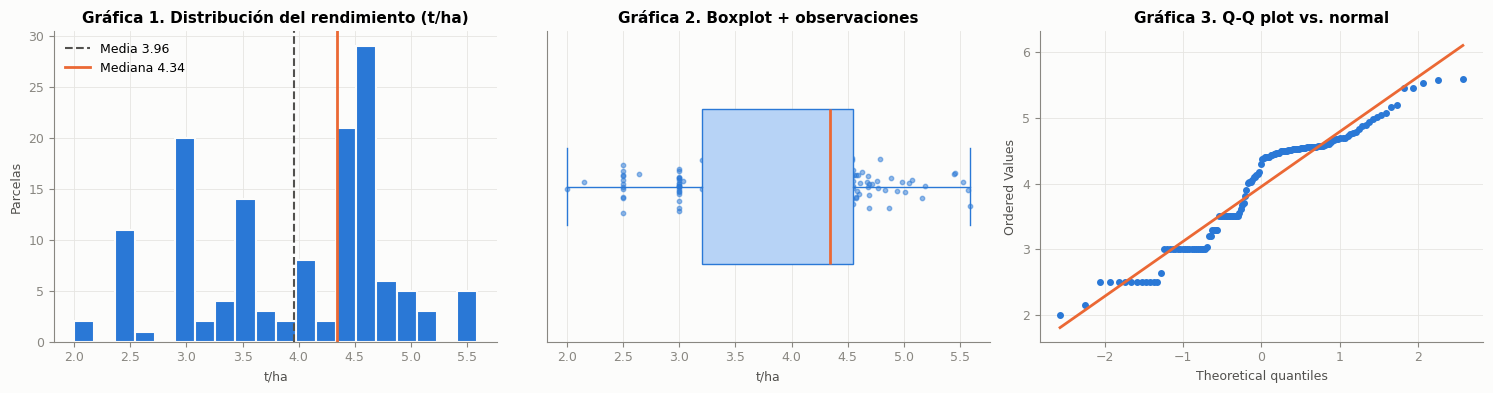

In [13]:
# Gráficas de distribución, boxplot y Q-Q plot del objetivo
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Gráfica 1: Histograma del objetivo
axes[0].hist(y, bins=20, color=AZUL, edgecolor="#fcfcfb", linewidth=1.5)
axes[0].axvline(y.mean(), color=GRIS_TXT, ls="--", lw=1.5, label=f"Media {y.mean():.2f}")
axes[0].axvline(y.median(), color=NARANJA, ls="-", lw=2, label=f"Mediana {y.median():.2f}")
axes[0].set_title("Gráfica 1. Distribución del rendimiento (t/ha)")
axes[0].set_xlabel("t/ha"); axes[0].set_ylabel("Parcelas"); axes[0].legend(frameon=False)

# Gráfica 2: Boxplot del objetivo con observaciones
axes[1].boxplot(y, vert=False, widths=0.5, patch_artist=True,
                boxprops=dict(facecolor="#b7d3f6", color=AZUL), medianprops=dict(color=NARANJA, lw=2),
                whiskerprops=dict(color=AZUL), capprops=dict(color=AZUL))
axes[1].scatter(y, np.random.normal(1, 0.04, len(y)), s=10, color=AZUL, alpha=0.5)
axes[1].set_title("Gráfica 2. Boxplot + observaciones"); axes[1].set_xlabel("t/ha"); axes[1].set_yticks([])

# Gráfica 3: Q-Q plot del objetivo vs. distribución normal
stats.probplot(y, dist="norm", plot=axes[2])
axes[2].get_lines()[0].set(color=AZUL, markersize=4)
axes[2].get_lines()[1].set(color=NARANJA, lw=2)
axes[2].set_title("Gráfica 3. Q-Q plot vs. normal")
plt.tight_layout(); plt.show()

#### [Interpretación]

- **Gráfica 1, distribución del rendimiento:** tiende a ser **bimodal**, con un grupo de parcelas con ~3 t/ha y otro con ~4.3–4.6 t/ha. Se explora agrupando el rendimiento en clases.
- **Gráfica 2, boxplot y observaciones (densidad empírica de los datos):** indica un sesgo negativo. La mediana se encuentra cerca del tercer cuartil, es decir, hay concentración de rendimientos elevados, pero los rendimientos bajos están más dispersos.
- **Gráfica 3, Q-Q plot vs. normal:** las desviaciones y los patrones escalonados de los puntos respecto a la línea diagonal teórica indican que el rendimiento no sigue una distribución normal.

**[Bibliografía]**
- Tukey, J. W. (1977). *Exploratory data analysis*. Addison-Wesley.

#### 2.3.2 Clustering de la variable `RENDIMIENTO_T_HA`

> **[Texto]** Derivado de la **Gráfica 1. Distribución del rendimiento**, donde se identificó que la distribución tiende a ser bimodal, se realiza una técnica de clustering (K-means, ver 2.1.B) para identificar grupos de rendimiento (alto/bajo).

In [14]:
# Clustering del objetivo para identificar grupos de rendimiento
km = KMeans(n_clusters=2, n_init=10, random_state=42).fit(y.to_frame())
train["grupo_rend"] = np.where(km.labels_ == np.argmax(km.cluster_centers_.ravel()), "Alto", "Bajo")
print(train.groupby("grupo_rend")[TARGET].describe().round(2))
print("\nUmbral aproximado entre grupos:",
      round(np.mean(sorted(km.cluster_centers_.ravel())), 2), "t/ha")

            count  mean   std   min   25%   50%   75%   max
grupo_rend                                                 
Alto         80.0  4.60  0.35  3.91  4.45  4.54  4.69  5.59
Bajo         58.0  3.07  0.43  2.00  3.00  3.00  3.50  3.81

Umbral aproximado entre grupos: 3.83 t/ha


#### 2.3.3 Rendimientos por municipio (`RENDIMIENTO_T_HA`)

> **[Texto]** Se utiliza la prueba de **Kruskal-Wallis** (ver 2.1.C).

                               count  mean  median   std
municipio                                               
Chignahuapan                      71  4.48    4.52  0.58
Calpulalpan                       30  3.00    3.00  0.37
Singuilucan                       16  3.08    3.20  0.43
Almoloya                          10  4.52    4.53  0.19
Cuautepec de Hinojosa              5  4.60    4.61  0.15
Emiliano Zapata                    3  3.50    3.50  0.00
Apan                               1  3.00    3.00   NaN
Nanacamilpa de Mariano Arista      1  2.50    2.50   NaN
Tepeapulco                         1  4.45    4.45   NaN

Kruskal-Wallis entre municipios con n ≥ 5:
Estadístico H = 81.13
Chi-cuadrada crítica (α=0.05, gl=4) = 9.49
Valor p = 1.00e-16
Conclusión: H > Chi-cuadrada crítica (Se rechaza H0, las medianas no son iguales)


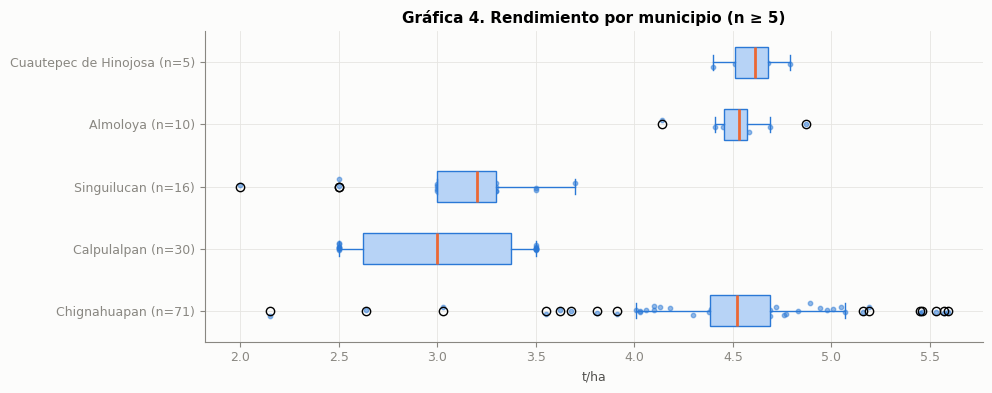

In [15]:
# Rendimiento por municipio (solo entrenamiento)
por_mun = train.groupby("municipio")[TARGET].agg(["count", "mean", "median", "std"]).sort_values("count", ascending=False)
print(por_mun.round(2))
mun_validos = por_mun[por_mun["count"] >= 5].index

# Prueba de Kruskal-Wallis para comparar el rendimiento entre municipios con n ≥ 5
kw = stats.kruskal(*[train.loc[train["municipio"] == m, TARGET] for m in mun_validos])

# Cálculo de Chi-cuadrada crítica
alpha = 0.05
grados_libertad = len(mun_validos) - 1
chi2_crit = stats.chi2.ppf(1 - alpha, grados_libertad)

# Impresión de resultados
print(f"\nKruskal-Wallis entre municipios con n ≥ 5:")
print(f"Estadístico H = {kw.statistic:.2f}")
print(f"Chi-cuadrada crítica (α={alpha}, gl={grados_libertad}) = {chi2_crit:.2f}")
print(f"Valor p = {kw.pvalue:.2e}")

if kw.statistic > chi2_crit:
    print("Conclusión: H > Chi-cuadrada crítica (Se rechaza H0, las medianas no son iguales)")
else:
    print("Conclusión: H <= Chi-cuadrada crítica (No se rechaza H0)")

# Gráfica 4: Boxplot del rendimiento por municipio (solo municipios con n ≥ 5)
fig, ax = plt.subplots(figsize=(10, 4))
datos = [train.loc[train["municipio"] == m, TARGET] for m in mun_validos]
ax.boxplot(datos, vert=False, widths=0.5, patch_artist=True,
           boxprops=dict(facecolor="#b7d3f6", color=AZUL), medianprops=dict(color=NARANJA, lw=2),
           whiskerprops=dict(color=AZUL), capprops=dict(color=AZUL))
for i, d in enumerate(datos, start=1):
    ax.scatter(d, np.random.normal(i, 0.05, len(d)), s=10, color=AZUL, alpha=0.5)
ax.set_yticks(range(1, len(mun_validos) + 1), [f"{m} (n={por_mun.loc[m, 'count']})" for m in mun_validos])
ax.set_title("Gráfica 4. Rendimiento por municipio (n ≥ 5)"); 
ax.set_xlabel("t/ha")
plt.tight_layout(); plt.show()

#### [Interpretación]

El rendimiento cambia mucho entre municipios:

- **Chignahuapan, Almoloya y Cuautepec** rondan 4.5 t/ha.
- **Calpulalpan y Singuilucan** rondan 3.0 t/ha (Kruskal-Wallis $p \approx 10^{-16}$). Estos dos últimos son también los que reportan valores redondeados.

Por eso la bimodalidad del objetivo coincide con la **zona** y con la **forma de registro**. Cualquier variable que cambie entre zonas (clima, suelo, altitud) va a parecer predictiva aunque no explique el rendimiento dentro de una misma zona.

La fuerte separación de las medianas entre los clústeres de alto rendimiento (Chignahuapan, Almoloya, Cuautepec) y de bajo rendimiento (Calpulalpan, Singuilucan) demuestra que la varianza inter-municipal domina la distribución. De no controlarse este efecto, los algoritmos utilizarán cualquier variable macro (como temperatura media o altitud) simplemente como un clasificador geográfico, ignorando las verdaderas señales agronómicas locales.

> **[Decisión de modelado]** La variable `municipio` debe excluirse.
>
> **M2 · Random Forest multifuente (candidato principal)**
> - **Técnica a usar:** exclusión deliberada.
> - **Implementación:** usar `StratifiedKFold` en scikit-learn con la nueva variable `grupo_rend` para hacer los cortes. No se usa la variable `municipio`, ya que generaría un error con los municipios que tengan menos de 5 parcelas.
> - **Justificación:** Random Forest tiende a sobreajustarse con variables categóricas de alta cardinalidad o fuertemente correlacionadas con el objetivo. Si se busca evaluar el verdadero poder predictivo de los sensores multifuente, una estrategia agresiva pero válida es eliminar por completo la variable `municipio` y el *target encoding* de las características de entrada. Esto fuerza al modelo a construir las reglas de decisión basándose estrictamente en las firmas espectrales y climáticas.

#### 2.3.4 Análisis de la resolución (`diag_y_resolucion`) y su efecto sobre `RENDIMIENTO_T_HA`

> **[Texto]** **¿Cómo se registró el rendimiento?** La tabla incluye la resolución del reporte (`diag_y_resolucion`):
> - **0.5 t/ha:** valor redondeado (estimación).
> - **0.1 o 0.01 t/ha:** valor medido con más precisión.
>
> Se utilizan la **Prueba exacta de Fisher** y la **Prueba de Kruskal-Wallis** (ver 2.1.C).

In [16]:
# Análisis de la resolución del reporte (diag_y_resolucion) por grupo de rendimiento
print(pd.crosstab(train["grupo_rend"], train["diag_y_resolucion"], margins=True,
                  rownames=["Grupo"], colnames=["Resolución del reporte (t/ha)"]))
print()
print(train.groupby("diag_y_resolucion")[TARGET].describe().round(2))

#Prueba de Kruskal-Wallis (Variable continua vs Categorías)
# Extraemos los arreglos de datos del TARGET para cada nivel de resolución
grupo_0_01 = train[train["diag_y_resolucion"] == 0.01][TARGET].dropna()
grupo_0_10 = train[train["diag_y_resolucion"] == 0.10][TARGET].dropna()
grupo_0_50 = train[train["diag_y_resolucion"] == 0.50][TARGET].dropna()

# Aplicamos la prueba para comparar las tres medianas
stat_kw, p_kw = stats.kruskal(grupo_0_01, grupo_0_10, grupo_0_50)

print("Prueba de Kruskal-Wallis")
print(f"Estadístico H: {stat_kw:.4f}")
print(f"p-valor: {p_kw:.4e}\n")

# Prueba Exacta de Fisher (Variables Categóricas)
# Generamos la tabla de contingencia aislando solo las frecuencias (sin márgenes)
tabla_contingencia = pd.crosstab(train["grupo_rend"], train["diag_y_resolucion"])
tabla_2x2 = tabla_contingencia.loc[:, [0.01, 0.50]]

stat_fisher, p_fisher = stats.fisher_exact(tabla_2x2)

print("Prueba Exacta de Fisher (0.01 vs 0.50)")
print(f"Tabla evaluada:\n{tabla_2x2}\n")
print(f"p-valor: {p_fisher:.4e}")

Resolución del reporte (t/ha)  0.01  0.1  0.5  All
Grupo                                             
Alto                             73    6    1   80
Bajo                              7    7   44   58
All                              80   13   45  138

                   count  mean   std   min   25%   50%   75%   max
diag_y_resolucion                                                 
0.01                80.0  4.50  0.55  2.15  4.44  4.54  4.69  5.59
0.10                13.0  3.78  0.54  3.20  3.30  3.70  4.30  4.60
0.50                45.0  3.03  0.46  2.00  2.50  3.00  3.50  4.50
Prueba de Kruskal-Wallis
Estadístico H: 83.9955
p-valor: 5.7626e-19

Prueba Exacta de Fisher (0.01 vs 0.50)
Tabla evaluada:
diag_y_resolucion  0.01  0.50
grupo_rend                   
Alto                 73     1
Bajo                  7    44

p-valor: 3.9041e-25


#### [Interpretación]

Casi todos los rendimientos reportados con resolución de **0.5 t/ha** (valores redondeados) caen en el grupo de **rendimiento bajo** (44 de 45), mientras que el grupo alto se reporta casi siempre con resolución de 0.01 t/ha. Esto indica que parte del rendimiento bajo fue **estimado o reportado de forma aproximada** y no medido, lo que añade ruido a la etiqueta.

> **[Estadística]**
>
> | Prueba | Valor *p* | Lectura |
> |---|---|---|
> | Kruskal-Wallis | $5.7626 \times 10^{-19}$ | Las medianas del rendimiento continuo difieren significativamente según el nivel de resolución con el que fueron reportadas. |
> | Exacta de Fisher | $3.9041 \times 10^{-25}$ | Dependencia estadística abrumadora entre la resolución del reporte y la categoría de rendimiento; los reportes de baja precisión (0.50) están fuertemente sesgados hacia los rendimientos bajos. |

> **[Decisión de modelado]** La variable `diag_y_resolucion` debe usarse como ponderador de error (*sample weight*) en el modelo de Random Forest. **NO INCLUIRLA COMO PREDICTORA.**
>
> **M2 · Random Forest multifuente (candidato principal):** pasar los pesos basados en la resolución al parámetro `sample_weight` durante el método `.fit()`. Esto hace que el bosque priorice la reducción de impureza en las muestras más precisas (0.01).

#### 2.3.5 Banderas de diagnóstico booleanas

*¿Cuántas parcelas están marcadas y si su rendimiento difiere?*

> **[Texto]** En este apartado se explica por qué las variables booleanas de diagnóstico se mantienen como diagnóstico y no se incluyeron dentro de las variables predictoras. Además, se determina cuáles tienen significancia estadística para mantenerlas como variables de control en un modelo de **Random Forest**.
>
> Se utiliza la prueba **U de Mann-Whitney** (ver 2.1.C) para determinar si existen diferencias estadísticamente significativas entre la distribución del rendimiento de las parcelas marcadas (presentan anomalía, `diag_*` = True) y el resto (no presentan la anomalía, `diag_*` = False).
>
> Dado que la variable objetivo presentó distribuciones con asimetría y diferencias marcadas en el tamaño de los subgrupos, se utilizó la prueba no paramétrica de Mann-Whitney U (Mann & Whitney, 1947; Siegel & Castellan, 1988) para contrastar las diferencias entre las observaciones marcadas y el resto de la muestra.

In [17]:
# Banderas de diagnóstico
filas = []
for c in [d for d in diagnosticos if df[d].dtype == bool]:
    marcadas = train.loc[train[c], TARGET]; 
    resto = train.loc[~train[c], TARGET]
    p = stats.mannwhitneyu(marcadas, resto).pvalue if len(marcadas) >= 3 else np.nan
    filas.append({"bandera": c, "n_total": int(df[c].sum()), "n_train": len(marcadas),
                  "rend_marcadas": marcadas.mean(), "rend_resto": resto.mean(), "p_mann_whitney": p})
pd.DataFrame(filas).set_index("bandera").round(3)

,n_total,n_train,rend_marcadas,rend_resto,p_mann_whitney
bandera,,,,,
diag_topo_pocos_pix,69,52,4.237,3.785,0.001
diag_topo_nodata,4,4,3.125,3.980,0.044
diag_sin_ciclo,0,0,NaN,3.955,NaN
diag_ciclo_ambiguo,1,0,NaN,3.955,NaN
diag_s2_sin_ciclo,0,0,NaN,3.955,NaN
diag_fenologia_discrepante,29,24,4.228,3.898,0.120
diag_era5_vecino,2,2,5.160,3.938,NaN


#### [Interpretación]

**Banderas estadísticamente significativas ($p < 0.05$)**

**`diag_topo_pocos_pix`** (menos de 2 píxeles en la topografía)

- **Datos:** la anomalía se presenta en 69 parcelas totales, de las cuales 52 son del conjunto de entrenamiento.
- **Comportamiento:** el rendimiento promedio de las parcelas marcadas (4.237) es superior al del resto (3.785).
- **Significancia:** el valor $p = 0.001$ indica una diferencia estadísticamente significativa.
- **Observación:** la escasez de píxeles en la topografía introduce un sesgo sistemático sobre la medición del rendimiento.

> **[Decisión de modelado]** Es recomendable utilizar `diag_topo_pocos_pix` como **variable predictora**, para analizar en dónde se equivoca el modelo. Se cuenta con una muestra considerable, el valor $p = 0.001 < 0.05$ es significativo y la diferencia entre el rendimiento de las marcadas y el del resto es de 11.9 %.

**`diag_topo_nodata`** (sin datos en la topografía)

- **Datos:** la anomalía se presenta en 4 parcelas totales, de las cuales 4 son del conjunto de entrenamiento.
- **Comportamiento:** el rendimiento promedio de las parcelas marcadas (3.125) es inferior al del resto (3.980).
- **Significancia:** el valor $p = 0.044$ indica una diferencia estadísticamente significativa.
- **Observación:** la falta de datos del DEM en el borde introduce un sesgo sistemático sobre la medición del rendimiento.

> **[Decisión de modelado]** Esta anomalía indica un impacto negativo al estimar el rendimiento; sin embargo, la muestra es pequeña, por lo que **no se usará como variable de control**. Se decidió dejarla como variable de diagnóstico: primero, para evitar *outliers*; segundo, porque el modelo de *machine learning* no podrá aprender con pocas muestras.

**Banderas sin significancia estadística**

**`diag_fenologia_discrepante`** (Planet y S2 difieren más de 15 días en SOS50 o en el pico)

- **Datos:** la anomalía se presenta en 29 parcelas totales, de las cuales 24 son del conjunto de entrenamiento.
- **Comportamiento:** el rendimiento promedio de las parcelas marcadas (4.228) es superior al del resto (3.898).
- **Significancia:** el valor $p = 0.120$ indica que no hay evidencia estadísticamente significativa.
- **Observación:** no existe evidencia estadística suficiente para afirmar que la discrepancia fenológica altere significativamente la distribución del rendimiento.

> **[Decisión de modelado]** Se decide **no usar como variable de control**.

**Banderas sin observaciones suficientes**

`diag_sin_ciclo`, `diag_ciclo_ambiguo`, `diag_s2_sin_ciclo` y `diag_era5_vecino`: al ser banderas que no alcanzan el mínimo de observaciones para la U de Mann-Whitney, se descartan automáticamente por falta de varianza.

> **[Decisión de modelado]** **No se usarán como variables de control.**

- - -

## 3. Área de la parcela (`AREA_HA`)

> **[Texto]** Para medir la relación entre el área y el rendimiento se utilizan los coeficientes de correlación de **Pearson** y **Spearman** (ver 2.1.D). Spearman es la medida adecuada cuando no se cumplen los supuestos de nivel de intervalo o razón, relación lineal y distribución bivariada normal.

**[Bibliografía]**
- Spearman, C. (1904). The proof and measurement of association between two things. *The American Journal of Psychology, 15*(1), 72–101. https://doi.org/10.2307/1412159

In [18]:
# Estadísticas descriptivas del área de los polígonos
print(df["AREA_HA"].describe().round(2))
print(f"Asimetría: {df['AREA_HA'].skew():.2f}")
print("\nParcelas más grandes:")
print(df.nlargest(5, "AREA_HA")[["ID_POLIGONO", "AREA_HA", TARGET, "CONJUNTO"]])


count    197.00
mean       6.60
std        7.44
min        0.35
25%        2.30
50%        5.46
75%        8.09
max       64.30
Name: AREA_HA, dtype: float64
Asimetría: 4.73

Parcelas más grandes:
    ID_POLIGONO    AREA_HA  RENDIMIENTO_T_HA       CONJUNTO
46      AGC_047  64.301532              4.45  ENTRENAMIENTO
64      AGC_065  60.882842               NaN     PREDICCION
40      AGC_041  25.127046              2.50  ENTRENAMIENTO
136     AGC_137  24.810588              4.54  ENTRENAMIENTO
34      AGC_035  23.797252              4.68  ENTRENAMIENTO


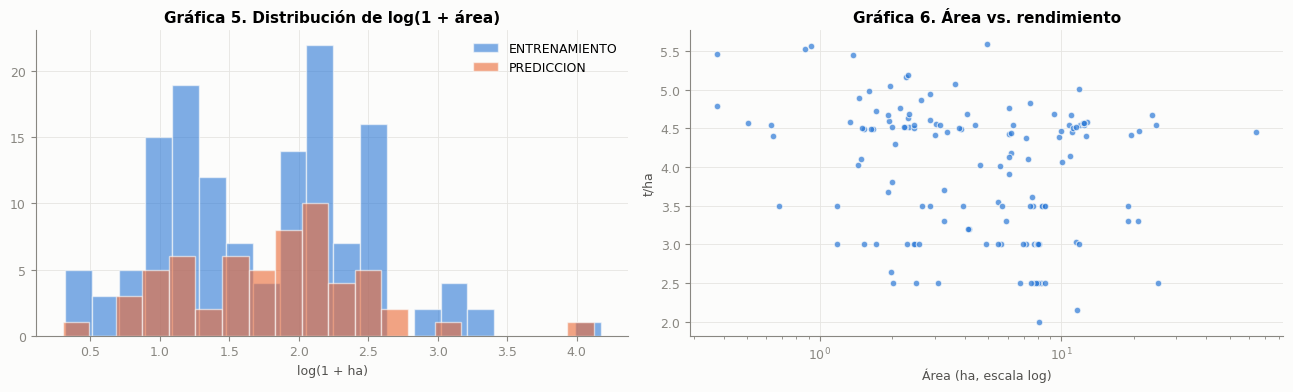

Pearson área-rendimiento:  -0.078
Spearman área-rendimiento: -0.249
Coeficiente de Spearman: -0.249
Valor p (p-value): 0.0032


In [19]:
# Gráfica 5: Distribución de log(1 + área)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for conj, g in df.groupby("CONJUNTO"):
    axes[0].hist(np.log1p(g["AREA_HA"]), bins=20, alpha=0.6, color=COLOR_CONJ[conj], label=conj,
                 edgecolor="#fcfcfb")
axes[0].set_title("Gráfica 5. Distribución de log(1 + área)"); axes[0].set_xlabel("log(1 + ha)")
axes[0].legend(frameon=False)

# Gráfica 6: Área vs. rendimiento
axes[1].scatter(train["AREA_HA"], y, s=22, color=AZUL, alpha=0.7, edgecolor="#fcfcfb", lw=0.8)
axes[1].set_xscale("log")
axes[1].set_title("Gráfica 6. Área vs. rendimiento"); axes[1].set_xlabel("Área (ha, escala log)"); axes[1].set_ylabel("t/ha")
plt.tight_layout(); plt.show()

print(f"Pearson área-rendimiento:  {train['AREA_HA'].corr(y):.3f}")
print(f"Spearman área-rendimiento: {train['AREA_HA'].corr(y, method='spearman'):.3f}")

# Calculamos el coeficiente de Spearman y su valor p
corr_s, p_value = spearmanr(train["AREA_HA"], y)

print(f"Coeficiente de Spearman: {corr_s:.3f}")
print(f"Valor p (p-value): {p_value:.4f}")

#### [Interpretación]

**Escala de la variable**

Se decide usar **escala logarítmica** para `AREA_HA`, debido a su alta asimetría positiva. Esto permite obtener una normalización y un comportamiento más simétrico.

**Relación con el rendimiento (débil y no lineal)**

> **[Estadística]**
>
> | Medida | Valor |
> |---|---|
> | Pearson | ≈ −0.08 |
> | Spearman | ≈ −0.25 |
> | Valor *p* (Spearman) | 0.0032 |

- El `AREA_HA` aumenta, pero el `RENDIMIENTO_T_HA` casi nunca aumenta: tendencia monotónica **negativa**. En promedio, las parcelas más grandes tienden a asociarse con menores rendimientos en términos de rangos.
- Con un valor *p* de 0.0032 existe evidencia estadística significativa de que la correlación es diferente de cero; es decir, la relación negativa no es producto del azar.
- El tamaño del área explica una porción muy pequeña de la variabilidad del rendimiento. Por sí sola aporta muy poca información predictiva útil para estimar el rendimiento (t/ha).

> **[Decisión de modelado]** La variable `AREA_HA` no requiere transformación para usarse en Random Forest.
>
> **M2 · Random Forest multifuente (candidato principal)**
> - **Técnica a usar:** ninguna transformación obligatoria; `AREA_HA` pasa en su escala original.
> - **Justificación:** los árboles de decisión son invariantes a transformaciones monótonas. Para Random Forest, dividir el nodo usando el valor original del área o su logaritmo produce exactamente el mismo resultado matemático en las particiones (*splits*). Una buena práctica complementaria es evaluar si `AREA_HA` funciona mejor al interactuar con otras variables (por ejemplo, índices de vegetación o índices climáticos por hectárea) para darle mayor poder predictivo al bosque.

- - -

## 4. Valores atípicos en los predictores (regla IQR)

> **[Texto]** Se identifican los valores atípicos con la regla del rango intercuartílico (ver 2.1.A).

In [20]:
# Identificación de valores atípicos
Q1 = df[predictoras].quantile(0.25); 
Q3 = df[predictoras].quantile(0.75); 
IQR = Q3 - Q1

# Se identifican los valores atípicos según la regla del IQR (1.5 * IQR)
mask_out = (df[predictoras] < Q1 - 1.5 * IQR) | (df[predictoras] > Q3 + 1.5 * IQR)
out_var = mask_out.sum().sort_values(ascending=False)
print(f"Variables con al menos un atípico: {(out_var > 0).sum()} de {len(predictoras)}")
print(out_var.head(15).to_frame("n_atipicos"))

# Conteo de valores atípicos por fila
out_fila = mask_out.sum(axis=1)
df_out = df.assign(n_atipicos=out_fila).sort_values("n_atipicos", ascending=False)
print("\nParcelas con más variables atípicas:")
print(df_out[["ID_POLIGONO", "CONJUNTO", "AREA_HA", TARGET, "n_atipicos"]].head(10))

Variables con al menos un atípico: 43 de 62
                            n_atipicos
pl_caida_intra_ciclo                36
dz_pixel_m                          28
ac_lluvia_max_dia_ciclo_mm          26
ac_lluvia_ciclo_mm                  25
pl_sos20_doy                        22
ac_dias_lluvia_ciclo                21
era5_rs_ciclo_mj_m2                 19
pl_n_picos                          19
ac_gdd_ciclo                        16
ac_lluvia_ciclo_anom_rel            16
ac_racha_seca_max_flor              16
era5_sm2_flor                       13
s2_sos50_doy                        12
AREA_HA                             11
pl_integral_ciclo                   11

Parcelas con más variables atípicas:
    ID_POLIGONO       CONJUNTO    AREA_HA  RENDIMIENTO_T_HA  n_atipicos
65      AGC_066  ENTRENAMIENTO   7.148586              3.00          16
62      AGC_063     PREDICCION  12.544529               NaN          14
174     AGC_175     PREDICCION   1.406628               NaN          13
158   

> **[Nota]** Para el modelo de Random Forest, los valores atípicos no representan ningún problema.

### 4.1 Coherencia del calendario fenológico (Planet)

> **[Texto]** Debe cumplirse: SOS20 ≤ SOS50 ≤ pico ≤ EOS50 ≤ EOS20.

Parcelas con las fases en orden: 197 de 197
pl_duracion_dias == EOS20 - SOS20 en todas las parcelas: True
Parcelas con más de un pico de NDVI (Planet / Sentinel-2): 19 / 7


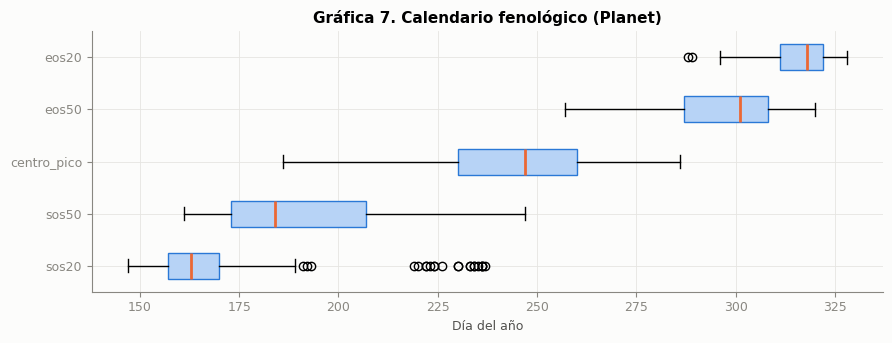

In [21]:
# Coherencia del calendario fenológico (Planet): debe cumplirse SOS20 ≤ SOS50 ≤ pico ≤ EOS50 ≤ EOS20
fases = ["pl_sos20_doy", "pl_sos50_doy", "pl_centro_pico_doy", "pl_eos50_doy", "pl_eos20_doy"]
orden_ok = (df[fases].diff(axis=1).iloc[:, 1:] >= 0).all(axis=1)
print(f"Parcelas con las fases en orden: {orden_ok.sum()} de {len(df)}")
print("pl_duracion_dias == EOS20 - SOS20 en todas las parcelas:",
      bool((df["pl_duracion_dias"] == df["pl_eos20_doy"] - df["pl_sos20_doy"]).all()))
print("Parcelas con más de un pico de NDVI (Planet / Sentinel-2):",
      int((df["pl_n_picos"] > 1).sum()), "/", int((df["s2_n_picos"] > 1).sum()))

# Gráfica 7: Boxplot del calendario fenológico (Planet)
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.boxplot([df[c] for c in fases], vert=False,
           patch_artist=True, boxprops=dict(facecolor="#b7d3f6", color=AZUL),
           medianprops=dict(color=NARANJA, lw=2))
ax.set_yticks(range(1, len(fases) + 1), [c.replace("pl_", "").replace("_doy", "") for c in fases])
ax.set_title("Gráfica 7. Calendario fenológico (Planet)"); ax.set_xlabel("Día del año")
plt.tight_layout(); plt.show()

#### [Interpretación]

- **Progresión cronológica coherente:** las fases siguen un orden secuencial claro que cumple con la lógica de un ciclo agrícola: inicio (`sos20`, `sos50`), máximo desarrollo (`centro_pico`) y fin de temporada o senescencia (`eos50`, `eos20`).
- **Inicio de temporada (SOS):** el comienzo temprano del reverdecimiento (`sos20`) tiene una mediana cercana al día 165, lo que indica que la mayoría de las parcelas inician a mediados de junio. Esta fase presenta una cantidad notable de valores atípicos tardíos entre los días 220 y 240. El `sos50` le sigue con una mediana alrededor del día 185 y un rango intercuartílico más amplio.
- **Pico del ciclo (`centro_pico`):** el máximo vigor vegetativo ocurre de manera más dispersa. El 50 % central de los datos se concentra entre los días 225 y 260, con una mediana alrededor del día 245 (principios de septiembre).
- **Fin de temporada (EOS):** el declive del cultivo inicia con el `eos50`, cuya mediana se ubica cerca del día 300, con una alta variabilidad hacia fechas más tempranas. El `eos20` muestra la distribución más compacta de todas al final del año, con una mediana en el día 318 (mediados de noviembre), un margen muy estrecho de variación y un par de valores atípicos tempranos.
- **Variabilidad entre parcelas:** las cajas más anchas en las fases intermedias (`sos50` y `centro_pico`) indican que las tasas de desarrollo varían considerablemente entre las parcelas analizadas. En contraste, el cierre de la temporada (`eos20`) tiende a sincronizarse mucho más entre todas las unidades.

- - -

## 5. Distribución de las variables predictoras: entrenamiento vs. predicción

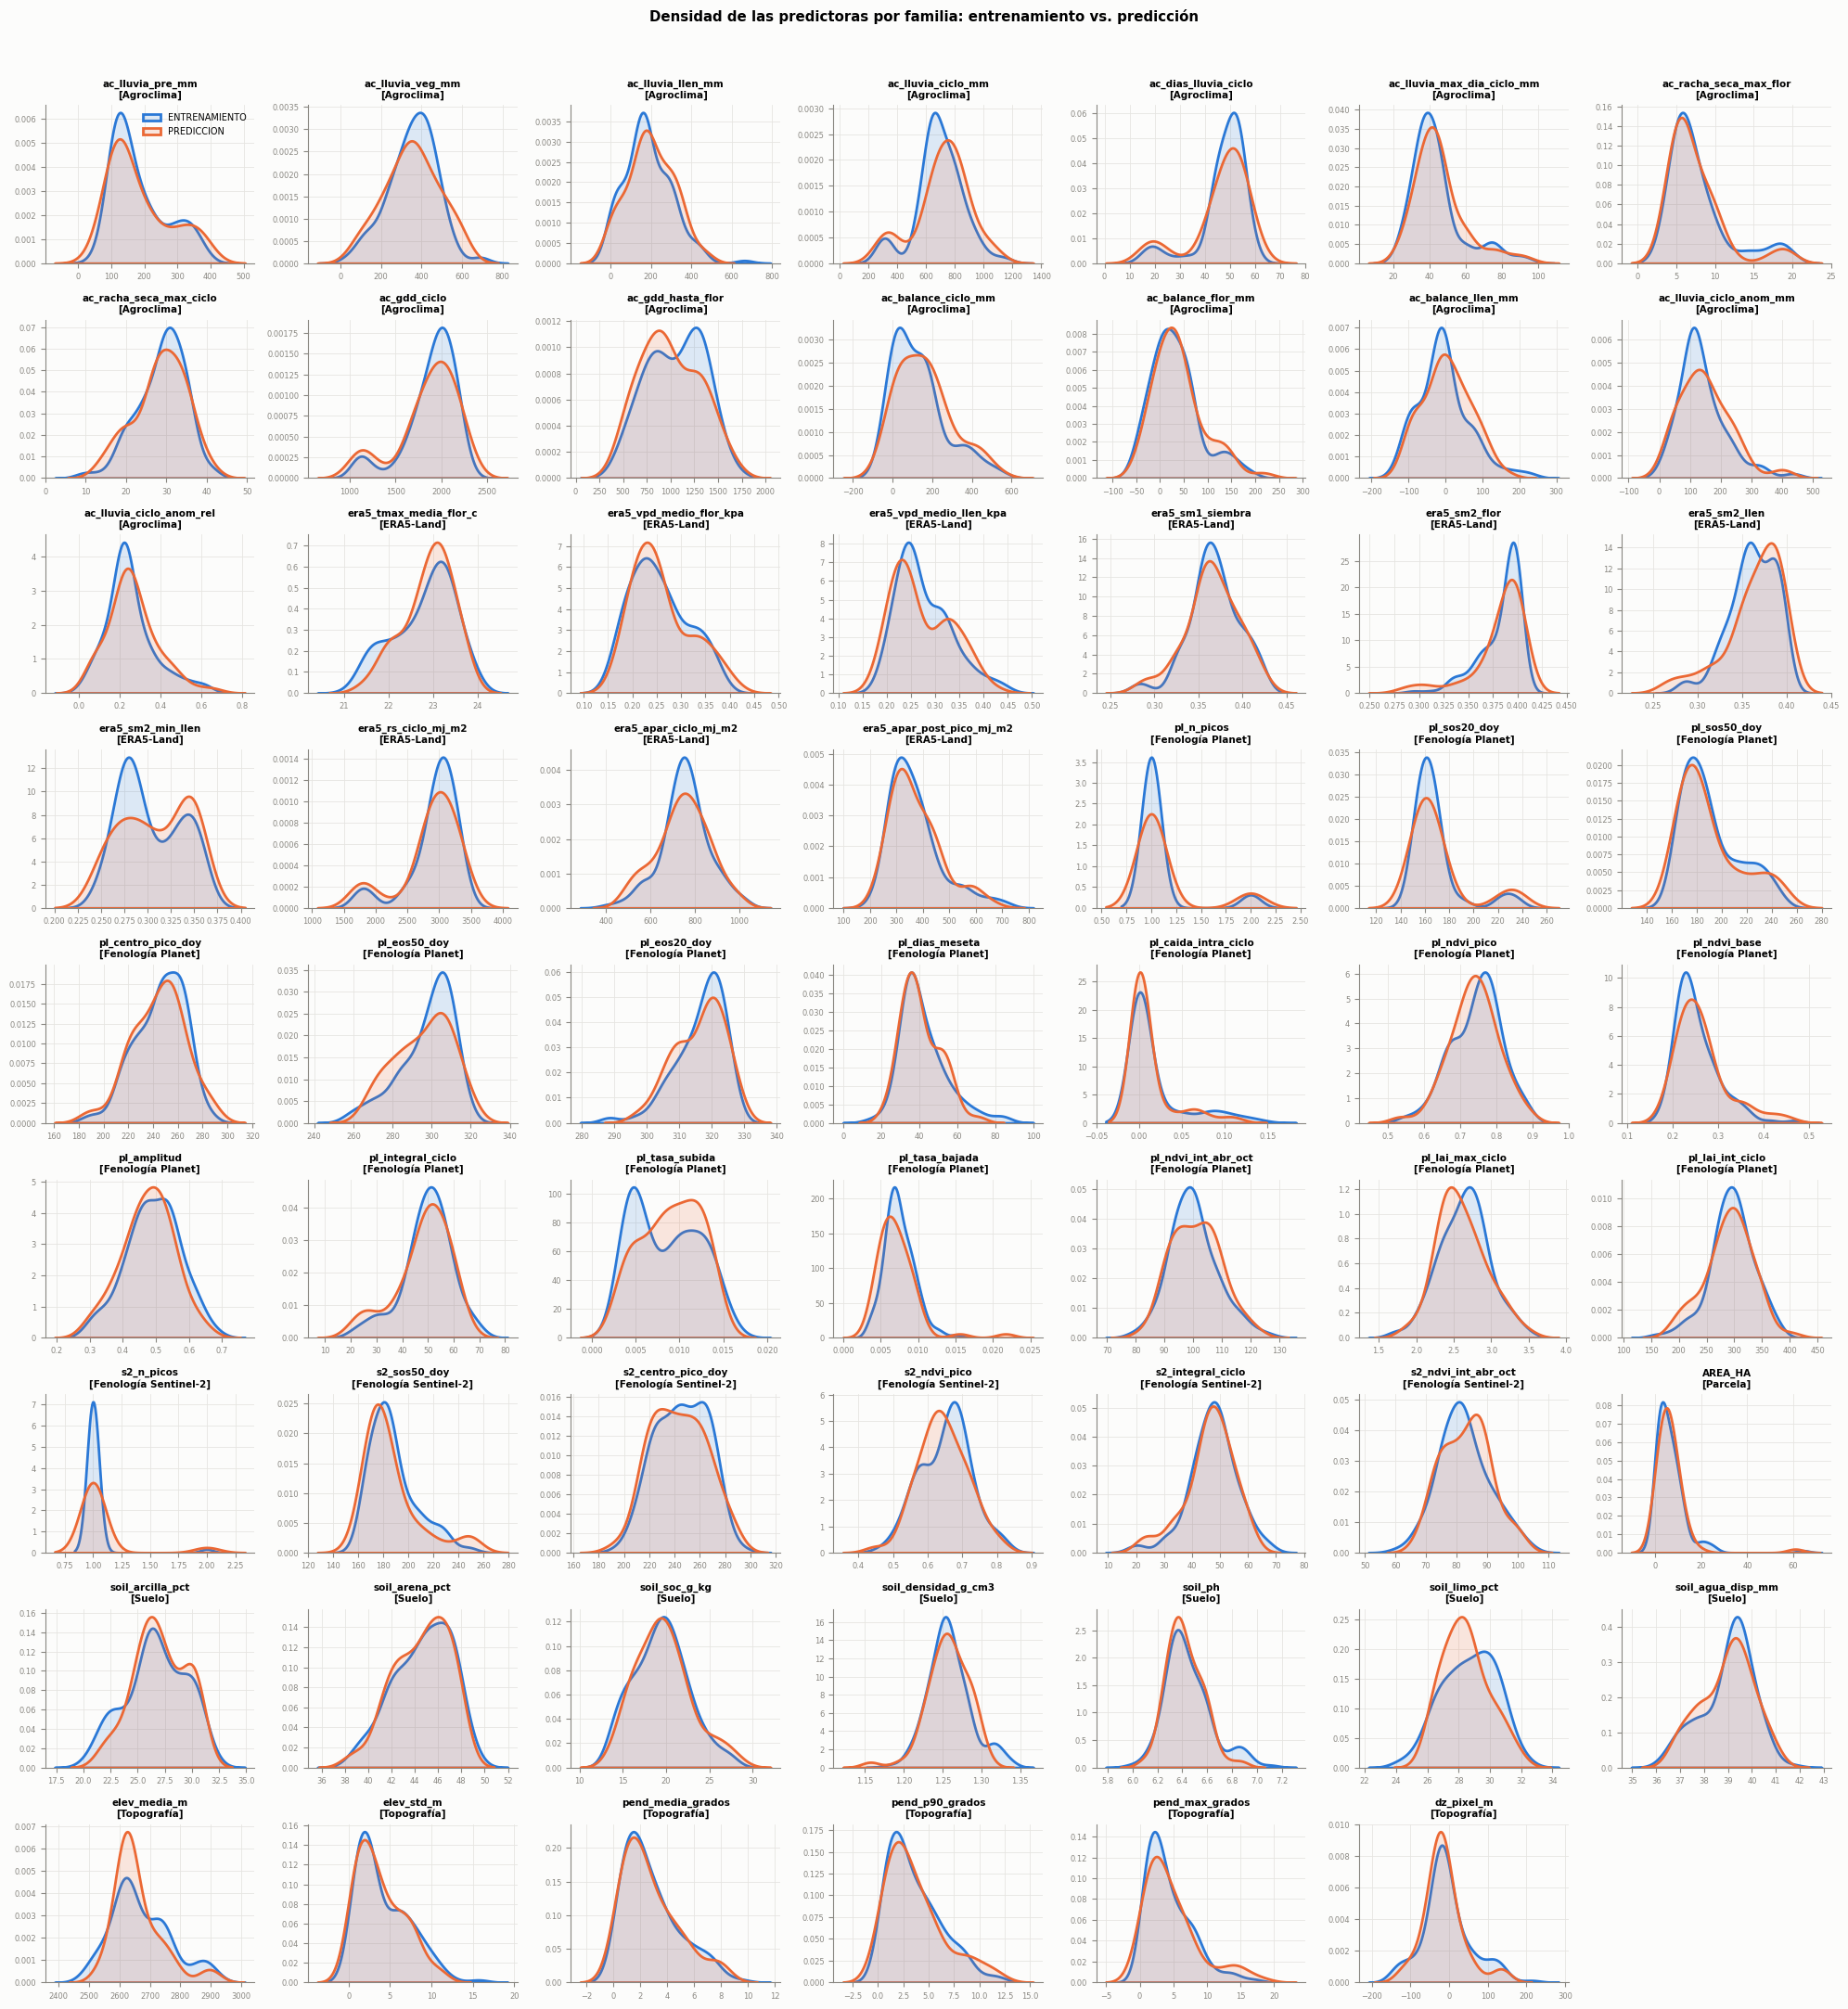

In [22]:
# Gráfica 8: Densidad de las predictoras por familia
orden_fam = meta.set_index("variable").loc[predictoras, "familia"].sort_values(kind="stable").index
n = len(orden_fam); ncol = 7; nrow = int(np.ceil(n / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(20, 2.4 * nrow))
for ax, c in zip(axes.ravel(), orden_fam):
    for conj, g in df.groupby("CONJUNTO"):
        sns.kdeplot(g[c], ax=ax, color=COLOR_CONJ[conj], lw=2, fill=True, alpha=0.15, label=conj, warn_singular=False)
    ax.set_title(f"{c}\n[{familia_de(c)}]", fontsize=7.5); ax.set_xlabel(""); ax.set_ylabel("")
    ax.tick_params(labelsize=6)
for ax in axes.ravel()[n:]:
    ax.set_visible(False)
axes.ravel()[0].legend(frameon=False, fontsize=7)
fig.suptitle("Densidad de las predictoras por familia: entrenamiento vs. predicción", fontweight="bold", y=1.0)
plt.tight_layout(rect=[0, 0, 1, 0.985]); 
plt.show()

#### [Interpretación]

En su mayoría, las variables predictoras del conjunto de entrenamiento mantienen una simetría con respecto a las del conjunto de predicción.

- - -

## 6. Relación de los predictores con el rendimiento

> **[Texto]** Se mide la correlación de Spearman entre cada predictora y el rendimiento (ver 2.1.D) y se corrige la significancia por comparaciones múltiples, primero con **Bonferroni** y después con **Benjamini-Hochberg**.

### 6.1 Corrección de Bonferroni

> **[Metodología]** Corrige la significancia cuando se realizan muchas pruebas a la vez (aquí, 62 correlaciones). Divide el valor $\alpha$ entre el número de pruebas realizadas. Es conservadora y puede pasar por alto algunos resultados significativos.

In [23]:
# Correlación de las variables predictoras con el objetivo
num_train = train[predictoras]
corr_p = num_train.corrwith(y)
corr_s = num_train.corrwith(y, method="spearman")
mi_tabla_B = pd.DataFrame({"pearson": corr_p, "spearman": corr_s})
mi_tabla_B["familia"] = [familia_de(c) for c in mi_tabla_B.index]
mi_tabla_B["|spearman|"] = mi_tabla_B["spearman"].abs()
mi_tabla_B = mi_tabla_B.sort_values("|spearman|", ascending=False)

# Significancia (Spearman) con corrección de Bonferroni
pvals = {c: stats.spearmanr(num_train[c], y).pvalue for c in predictoras}
mi_tabla_B["p_valor"] = pd.Series(pvals)
mi_tabla_B["signif_bonferroni"] = mi_tabla_B["p_valor"] < 0.05 / len(predictoras)
print(mi_tabla_B.head(25).round(4))
print(f"\nVariables significativas tras Bonferroni: {mi_tabla_B['signif_bonferroni'].sum()}")
print(f"Variables con p < 0.05 sin corregir: {(mi_tabla_B['p_valor'] < 0.05).sum()}")

                         pearson  spearman               familia  |spearman|  p_valor  signif_bonferroni
era5_vpd_medio_flor_kpa  -0.6611   -0.6407             ERA5-Land      0.6407   0.0000               True
ac_lluvia_pre_mm         -0.5961   -0.5783             Agroclima      0.5783   0.0000               True
era5_sm2_flor             0.5326    0.5398             ERA5-Land      0.5398   0.0000               True
soil_agua_disp_mm         0.5494    0.5142                 Suelo      0.5142   0.0000               True
soil_soc_g_kg             0.4648    0.4587                 Suelo      0.4587   0.0000               True
pl_eos50_doy              0.4084    0.4404      Fenología Planet      0.4404   0.0000               True
pl_eos20_doy              0.3891    0.4170      Fenología Planet      0.4170   0.0000               True
soil_densidad_g_cm3      -0.3640   -0.3975                 Suelo      0.3975   0.0000               True
ac_gdd_ciclo              0.2753    0.3974             

### 6.2 Corrección de Benjamini-Hochberg (FDR)

> **[Metodología]** Controla la tasa de falsos descubrimientos entre múltiples pruebas de hipótesis. Permite aceptar una proporción pequeña y controlada de falsos positivos a cambio de detectar una mayor cantidad de efectos reales.

**[Bibliografía]**
- Benjamini, Y., & Hochberg, Y. (1995). Controlling the false discovery rate: A practical and powerful approach to multiple testing. *Journal of the Royal Statistical Society: Series B (Methodological), 57*(1), 289–300. https://doi.org/10.1111/j.2517-6161.1995.tb02031.x
- Dunn, O. J. (1961). Multiple comparisons among means. *Journal of the American Statistical Association, 56*(293), 52–64. https://doi.org/10.1080/01621459.1961.10482090

In [24]:
# Correlación de las variables predictoras con el objetivo
num_train = train[predictoras]
corr_p = num_train.corrwith(y)
corr_s = num_train.corrwith(y, method="spearman")
mi_tabla_BH = pd.DataFrame({"pearson": corr_p, "spearman": corr_s})
mi_tabla_BH["familia"] = [familia_de(c) for c in mi_tabla_BH.index]
mi_tabla_BH["|spearman|"] = mi_tabla_BH["spearman"].abs()

# Calcular p-valores originales (Spearman)
pvals = {c: stats.spearmanr(num_train[c], y).pvalue for c in predictoras}
mi_tabla_BH["p_valor"] = pd.Series(pvals)

# multipletests devuelve una tupla. El segundo elemento son los p-valores ya corregidos.
rechazar, p_ajustados, _, _ = multipletests(
    mi_tabla_BH["p_valor"], 
    alpha=0.05, 
    method="fdr_bh"  # Benjamini-Hochberg
)

mi_tabla_BH["p_valor_fdr"] = p_ajustados
mi_tabla_BH["signif_fdr"] = rechazar

# Ordenar resltados
mi_tabla_BH = mi_tabla_BH.sort_values("|spearman|", ascending=False)

print(mi_tabla_BH.head(37).round(4))
print(f"\nVariables significativas tras FDR (Benjamini-Hochberg): {mi_tabla_BH['signif_fdr'].sum()}")
print(f"Variables con p < 0.05 sin corregir: {(mi_tabla_BH['p_valor'] < 0.05).sum()}")


                         pearson  spearman               familia  |spearman|  p_valor  p_valor_fdr  signif_fdr
era5_vpd_medio_flor_kpa  -0.6611   -0.6407             ERA5-Land      0.6407   0.0000       0.0000        True
ac_lluvia_pre_mm         -0.5961   -0.5783             Agroclima      0.5783   0.0000       0.0000        True
era5_sm2_flor             0.5326    0.5398             ERA5-Land      0.5398   0.0000       0.0000        True
soil_agua_disp_mm         0.5494    0.5142                 Suelo      0.5142   0.0000       0.0000        True
soil_soc_g_kg             0.4648    0.4587                 Suelo      0.4587   0.0000       0.0000        True
pl_eos50_doy              0.4084    0.4404      Fenología Planet      0.4404   0.0000       0.0000        True
pl_eos20_doy              0.3891    0.4170      Fenología Planet      0.4170   0.0000       0.0000        True
soil_densidad_g_cm3      -0.3640   -0.3975                 Suelo      0.3975   0.0000       0.0000        True
a

#### [Interpretación]

> **[Estadística]** Con la prueba de Benjamini-Hochberg aumentan las variables predictoras significativas de 16 (Bonferroni) a 34, con solo 3 falsos positivos.

Ahora se mantienen 34 variables significativas. Se recomienda probar ambos conjuntos.

In [25]:
# Filtrar las variables que NO eran significativas desde el inicio (p_valor >= 0.05)
tabla_descartadas_inicio = mi_tabla_BH[mi_tabla_BH["p_valor"] >= 0.05]

# Ordenar por la fuerza de correlación (las más cercanas a 0 primero)
tabla_descartadas_inicio = tabla_descartadas_inicio.sort_values("|spearman|", ascending=True)

# Imprimir la tabla completa de las 25 variables
print("VARIABLES DESCARTADAS DESDE EL INICIO (25 en total)")
print(tabla_descartadas_inicio.round(4))

# Verificación rápida del conteo
print(f"\nTotal de variables en esta tabla: {len(tabla_descartadas_inicio)}")


VARIABLES DESCARTADAS DESDE EL INICIO (25 en total)
                            pearson  spearman               familia  |spearman|  p_valor  p_valor_fdr  signif_fdr
pl_tasa_bajada               0.0212   -0.0130      Fenología Planet      0.0130   0.8801       0.8801       False
s2_integral_ciclo            0.0168    0.0189  Fenología Sentinel-2      0.0189   0.8261       0.8396       False
soil_arcilla_pct            -0.0725   -0.0207                 Suelo      0.0207   0.8100       0.8370       False
ac_lluvia_ciclo_mm          -0.1042   -0.0261             Agroclima      0.0261   0.7614       0.8001       False
s2_n_picos                   0.0231    0.0275  Fenología Sentinel-2      0.0275   0.7488       0.8001       False
pl_integral_ciclo           -0.0167   -0.0286      Fenología Planet      0.0286   0.7388       0.8001       False
ac_racha_seca_max_ciclo     -0.0323   -0.0384             Agroclima      0.0384   0.6548       0.7250       False
ac_lluvia_max_dia_ciclo_mm  -0.2268 

#### [Interpretación]

Estas 25 variables, de acuerdo con el coeficiente de correlación de Spearman, no son estadísticamente significativas; por lo tanto, la correlación real es cero.

> **[Nota]** Para el modelo **Random Forest** lo ideal es considerar las 62 variables originales en una primera etapa y permitir que el propio algoritmo evalúe la importancia de cada una mediante el método de *Feature Importance* (importancia de las características).

### 6.3 Variables con mayor correlación y desempeño por familia

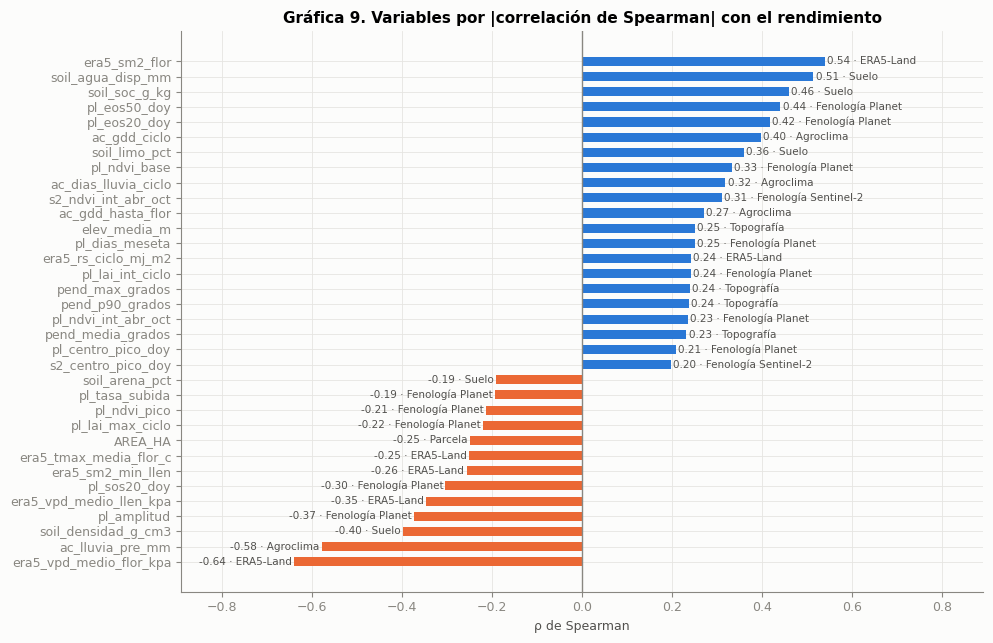

In [26]:
# Gráfica 9. de las 34 variables con correlación de Spearman (positiva o negativa) con el rendimiento
top = mi_tabla_BH.head(34).sort_values("spearman")
fig, ax = plt.subplots(figsize=(10, 6.5))
colores = [NARANJA if v < 0 else AZUL for v in top["spearman"]]
ax.barh(top.index, top["spearman"], color=colores, height=0.6)
ax.axvline(0, color=GRIS_EJE, lw=1)
for i, (v, s) in enumerate(zip(top["spearman"], top["familia"])):
    ax.text(v + (0.005 if v >= 0 else -0.005), i, f"{v:.2f} · {s}", va="center",
            ha="left" if v >= 0 else "right", fontsize=7.5, color=GRIS_TXT)
lim = top["spearman"].abs().max() + 0.25
ax.set_title("Gráfica 9. Variables por |correlación de Spearman| con el rendimiento")
ax.set_xlabel("ρ de Spearman"); ax.set_xlim(-lim, lim)
plt.tight_layout(); plt.show()

In [27]:
# Correlación absoluta media y máxima por familia de variables
print(mi_tabla_BH.groupby("familia")["|spearman|"].agg(["mean", "max", "count"]).sort_values("max", ascending=False).round(3))
print()
print("Variable más correlacionada de cada familia:")
print(mi_tabla_BH.reset_index(names="variable").groupby("familia").first()[["variable", "spearman", "p_valor"]]
      .sort_values("spearman", key=abs, ascending=False).round(4))

                       mean    max  count
familia                                  
ERA5-Land             0.287  0.641     10
Agroclima             0.172  0.578     15
Suelo                 0.285  0.514      7
Fenología Planet      0.229  0.440     17
Fenología Sentinel-2  0.143  0.310      6
Topografía            0.193  0.251      6
Parcela               0.249  0.249      1

Variable más correlacionada de cada familia:
                                     variable  spearman  p_valor
familia                                                         
ERA5-Land             era5_vpd_medio_flor_kpa   -0.6407   0.0000
Agroclima                    ac_lluvia_pre_mm   -0.5783   0.0000
Suelo                       soil_agua_disp_mm    0.5142   0.0000
Fenología Planet                 pl_eos50_doy    0.4404   0.0000
Fenología Sentinel-2      s2_ndvi_int_abr_oct    0.3104   0.0002
Topografía                       elev_media_m    0.2512   0.0030
Parcela                               AREA_HA   -0.2494 

#### [Interpretación]

> **[Texto]** Estos resultados muestran un análisis de correlación de Spearman diseñado para identificar el poder predictivo de distintas fuentes de datos climáticos, edáficos y satelitales sobre una variable objetivo, característico de los modelos de rendimiento agrícola.

**Desempeño general por familia de datos**

- Las familias **ERA5-Land** y **Suelo** tienen el **mayor poder predictivo**. Son las más consistentes, con las correlaciones medias más altas (0.287 y 0.285, respectivamente).
- **ERA5-Land** es la **familia dominante**: contiene la característica individual con la correlación máxima más alta (0.641) de todo el conjunto.
- **Fenología Planet** es la familia con más características procesadas (17 variables), seguida de **Agroclima** (15 variables).

**Interpretación de las variables más correlacionadas**

Todas las variables principales de cada familia son estadísticamente significativas, ya que sus valores *p* son sumamente bajos (todos $\le$ 0.0032).

- **Estrés térmico e hídrico (ERA5-Land y Agroclima):** el déficit de presión de vapor medio durante la floración (`era5_vpd_medio_flor_kpa`) presenta la correlación más fuerte del análisis (−0.6407). Esta relación negativa indica que un mayor estrés desecante en la atmósfera durante una etapa fenológica crítica penaliza drásticamente el resultado. La lluvia previa (`ac_lluvia_pre_mm`) también muestra una fuerte influencia negativa (−0.5783).
- **Condiciones del suelo:** el agua disponible en el suelo (`soil_agua_disp_mm`) tiene una sólida correlación positiva de 0.5142. Una mayor capacidad de retención y disponibilidad de humedad en el terreno favorece directamente el desempeño del cultivo.
- **Teledetección satelital (Planet y Sentinel-2):** el fin de la temporada (`pl_eos50_doy`) medido por Planet tiene una correlación positiva de 0.4404, lo que sugiere que los ciclos de cultivo más largos y sostenidos mejoran los resultados. Igualmente, la integral del índice de vegetación de abril a octubre obtenida por Sentinel-2 (`s2_ndvi_int_abr_oct`) se asocia positivamente (0.3104), lo que valida que un mayor vigor y biomasa acumulada se traducen en mejores métricas finales.
- **Geometría y terreno:** la elevación media (`elev_media_m`) y el tamaño del polígono (`AREA_HA`) tienen los impactos más bajos del grupo (0.2512 y −0.2494, respectivamente). Aunque su efecto es menor que el de los factores climáticos, siguen aportando información estructuralmente útil al modelo.

**[Bibliografía]**
- Corak, N. K., Thornton, P. E., & Lowman, L. E. L. (2025). A high resolution, gridded product for vapor pressure deficit using Daymet. *Scientific Data, 12*, Artículo 4544. https://doi.org/10.1038/s41597-025-04544-5
- Hara, P., Piekutowska, M., & Niedbała, G. (2021). Selection of independent variables for crop yield prediction using artificial neural network models with remote sensing data. *Land, 10*(6), 609. https://doi.org/10.3390/land10060609
- Li, H. Y. (2025). A framework for accurate food crop yield prediction from Sentinel-2 imagery. *Preprints*, Artículo 202511.0749. https://www.preprints.org/manuscript/202511.0749

### 6.4 Gráficas de dispersión de las variables con mayor correlación

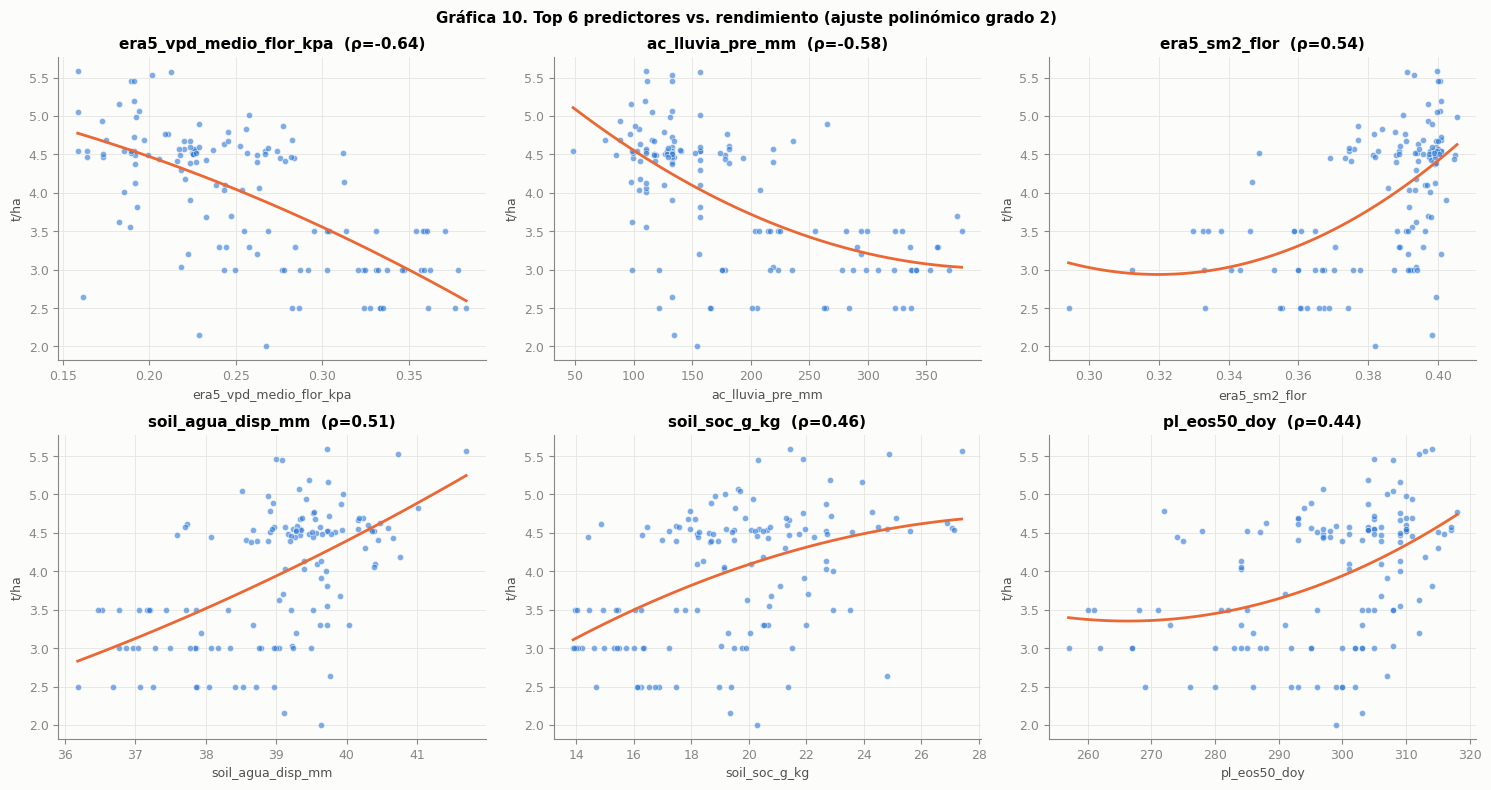

In [28]:
# Gráficas de dispersión de las 6 variables con mayor correlación de Spearman (positiva o negativa) con el rendimiento
top6 = mi_tabla_BH.head(6).index
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), top6):
    ax.scatter(train[c], y, s=20, color=AZUL, alpha=0.6, edgecolor="#fcfcfb", lw=0.6)
    sns.regplot(x=train[c], y=y, ax=ax, scatter=False, order=2, ci=None, color=NARANJA, line_kws={"lw": 2})
    ax.set_title(f"{c}  (ρ={mi_tabla_BH.loc[c, 'spearman']:.2f})"); ax.set_xlabel(c); ax.set_ylabel("t/ha")
fig.suptitle("Gráfica 10. Top 6 predictores vs. rendimiento (ajuste polinómico grado 2)", fontweight="bold")
plt.tight_layout(); plt.show()

#### [Interpretación]

**Interpretación de las relaciones predictivas**

- **Estrés atmosférico (ERA5-Land):** el déficit de presión de vapor durante la floración (`era5_vpd_medio_flor_kpa`) exhibe una tendencia negativa casi estrictamente lineal. A medida que el VPD aumenta, el rendimiento decae de forma constante, lo que indica que el estrés desecante en la atmósfera durante la etapa reproductiva penaliza directamente el llenado del grano.
- **Humedad del suelo (ERA5-Land y Suelo):** la humedad del suelo en la segunda capa durante la floración (`era5_sm2_flor`) muestra una relación no lineal acelerada. Los rendimientos más altos (superiores a 4 t/ha) se concentran exponencialmente cuando este índice supera el umbral de 0.38. Asimismo, el agua disponible en el suelo (`soil_agua_disp_mm`) presenta un crecimiento positivo sostenido, lo que confirma que la reserva hídrica del perfil del suelo es un motor principal del rendimiento.
- **Salud y estructura del suelo:** el carbono orgánico del suelo (`soil_soc_g_kg`) muestra un efecto de rendimientos marginales decrecientes. La curva polinómica indica que el incremento inicial de carbono orgánico (de 14 a 22 g/kg) eleva significativamente el rendimiento, pero la curva tiende a estabilizarse en los valores más altos, lo que sugiere un límite biológico o físico en su impacto.
- **Duración del ciclo fenológico:** el día del año del fin de la temporada medido por Planet (`pl_eos50_doy`) revela una relación convexa. Retrasar el fin de la madurez (hacia los días 300-320) se asocia con un aumento pronunciado en las toneladas por hectárea, lo que evidencia que los ciclos con un periodo de llenado de grano más prolongado alcanzan los máximos productivos.

**[Bibliografía]**
- Oldfield, E. E., Bradford, M. A., & Wood, S. A. (2019). Global meta-analysis of the relationship between soil organic matter and crop yields. *SOIL, 5*(1), 15–32. https://doi.org/10.5194/soil-5-15-2019
- Yuan, W., Zheng, Y., Piao, S., Ciais, P., Lombardozzi, D., Wang, Y., ... & Yang, S. (2019). Increased atmospheric vapor pressure deficit reduces global vegetation growth. *Science Advances, 5*(8), eaax1396. https://doi.org/10.1126/sciadv.aax1396
- Zeng, L., Wardlow, B. D., Xiang, D., Hu, S., & Li, D. (2020). A review of vegetation phenological metrics extraction using time-series, multispectral satellite data. *Remote Sensing of Environment, 237*, 111511. https://doi.org/10.1016/j.rse.2019.111511

### 6.5 Comparación de los mejores predictores entre grupos de rendimiento Alto vs. Bajo (Mann-Whitney)

> **[Texto]** Se aplica la prueba U de Mann-Whitney (ver 2.1.C) a las 34 variables significativas, comparando el grupo de rendimiento alto contra el bajo.

In [29]:
# Comparación de los top predictores entre grupos de rendimiento Alto vs. Bajo (Mann-Whitney)
filas = []
for c in mi_tabla_BH.head(34).index:
    a = train.loc[train.grupo_rend == "Alto", c]; b = train.loc[train.grupo_rend == "Bajo", c]
    u = stats.mannwhitneyu(a, b)
    filas.append({"variable": c, "mediana_alto": a.median(), "mediana_bajo": b.median(), "p_valor": u.pvalue})
pd.DataFrame(filas).set_index("variable").round(4)

,mediana_alto,mediana_bajo,p_valor
variable,,,
era5_vpd_medio_flor_kpa,0.2233,0.3036,0.0000
ac_lluvia_pre_mm,129.4324,258.5346,0.0000
era5_sm2_flor,0.3969,0.3694,0.0000
soil_agua_disp_mm,39.5122,38.2443,0.0000
soil_soc_g_kg,20.2376,17.0523,0.0000
pl_eos50_doy,305.0000,294.0000,0.0000
pl_eos20_doy,320.5000,314.5000,0.0000
soil_densidad_g_cm3,1.2508,1.2691,0.0000
ac_gdd_ciclo,2025.5856,1814.3789,0.0000


#### [Interpretación]

- **Déficit de presión de vapor y estrés hídrico (VPD):** el grupo de alto rendimiento experimentó un menor déficit de presión de vapor durante etapas críticas como la floración (`era5_vpd_medio_flor_kpa`: 0.2233 vs. 0.3036) y el llenado (`era5_vpd_medio_llen_kpa`). Un VPD alto incrementa la demanda atmosférica de agua, lo que provoca que la planta pierda agua excesivamente y limite su asimilación de carbono. La investigación agronómica confirma que un VPD alto durante la floración tiene un efecto negativo severo en el cuajado de la semilla y reduce significativamente el rendimiento.
- **Calidad del suelo y carbono orgánico:** el grupo superior cuenta con una mayor concentración de carbono orgánico en el suelo (`soil_soc_g_kg`: 20.23 vs. 17.05) y una capacidad ligeramente mayor de agua disponible (`soil_agua_disp_mm`: 39.51 vs. 38.24). Múltiples estudios respaldan que el aumento en los porcentajes de carbono orgánico en las capas superficiales del suelo favorece la retención de agua, fomenta la salud del cultivo y aumenta el rendimiento agrícola general.
- **Duración del ciclo y acumulación térmica (GDD):** el grupo de alto rendimiento acumuló notablemente más grados día de crecimiento durante su ciclo (`ac_gdd_ciclo`: 2025.5 vs. 1814.3) y hasta la floración (`ac_gdd_hasta_flor`). Esto coincide con las fechas fenológicas: iniciaron la temporada antes (`pl_sos20_doy`: 159 vs. 167) y terminaron después (`pl_eos50_doy`: 305 vs. 294). Los modelos basados en grados día de crecimiento (GDD) son herramientas fundamentales en la agronomía: a mayor acumulación térmica (sin llegar a temperaturas de estrés extremo), la planta tiene más tiempo para su desarrollo vegetativo y maduración, lo que se traduce directamente en un mayor potencial de rendimiento.
- **Desarrollo del dosel vegetativo:** los índices de verdor o biomasa, como la integral del NDVI (`s2_ndvi_int_abr_oct`, `pl_ndvi_int_abr_oct`), son marcadamente superiores en el grupo de alto rendimiento. Esto confirma que estas plantas generaron y mantuvieron una mayor área fotosintéticamente activa durante más tiempo.
- **Anomalía en precipitación previa:** se observa un resultado contraintuitivo. La lluvia acumulada previa a la siembra (`ac_lluvia_pre_mm`) es menor en el grupo de alto rendimiento (129.4 vs. 258.5). Esto sugiere que, aunque el grupo alto tuvo más días de lluvia durante el ciclo productivo (`ac_dias_lluvia_ciclo`: 52 vs. 46), un exceso de precipitación antes de la siembra en el grupo bajo pudo haber causado problemas de anegamiento de suelos, retraso en siembras o lixiviación temprana de nutrientes.

**[Bibliografía]**
- McMaster, G. S., & Wilhelm, W. W. (1997). Growing degree-days: one equation, two interpretations. *Agricultural and Forest Meteorology, 87*(4), 291-300.

- - -

## 7. Multicolinealidad entre predictores

In [30]:
# Correlación entre las variables predictoras
corr_mat = df[predictoras].corr()
sup = corr_mat.where(np.triu(np.ones(corr_mat.shape, dtype=bool), k=1)).stack()
pares = sup.abs().sort_values(ascending=False)
print(f"Pares totales: {len(pares)}")
for u in [0.99, 0.95, 0.90, 0.80]:
    print(f"  |r| > {u}: {(pares > u).sum()} pares")
print("\nPares más correlacionados:")
print(sup.loc[pares.head(20).index].round(4))

Pares totales: 1891
  |r| > 0.99: 0 pares
  |r| > 0.95: 6 pares
  |r| > 0.9: 17 pares
  |r| > 0.8: 40 pares

Pares más correlacionados:
pl_sos20_doy                ac_dias_lluvia_ciclo       -0.9722
pl_ndvi_int_abr_oct         s2_ndvi_int_abr_oct         0.9667
ac_gdd_ciclo                era5_rs_ciclo_mj_m2         0.9646
pl_ndvi_pico                s2_ndvi_pico                0.9623
pend_media_grados           pend_p90_grados             0.9558
pl_lai_int_ciclo            era5_apar_ciclo_mj_m2       0.9525
pl_sos20_doy                era5_rs_ciclo_mj_m2        -0.9462
                            ac_gdd_ciclo               -0.9421
ac_dias_lluvia_ciclo        ac_gdd_ciclo                0.9415
pend_p90_grados             pend_max_grados             0.9360
ac_dias_lluvia_ciclo        era5_rs_ciclo_mj_m2         0.9338
pl_centro_pico_doy          ac_lluvia_llen_mm          -0.9280
pl_ndvi_pico                pl_lai_max_ciclo            0.9266
ac_lluvia_ciclo_anom_mm     ac_lluvia_ciclo_a

#### [Interpretación]

> **[Estadística]** De los 1891 pares de variables evaluados:
>
> | Umbral | Pares |
> |---|---|
> | $\vert r\vert > 0.99$ | 0 |
> | $\vert r\vert > 0.95$ | 6 |
> | $\vert r\vert > 0.90$ | 17 |
> | $\vert r\vert > 0.80$ | 40 |

- **Resumen de colinealidad:** ningún par presenta una correlación casi perfecta, pero existe un subconjunto con alta dependencia lineal.
- **Correlación más fuerte:** la relación más intensa es negativa ($r = -0.9722$) entre el inicio de la temporada (`pl_sos20_doy`) y los días de lluvia del ciclo (`ac_dias_lluvia_ciclo`).
- **Redundancia de información:** se observa una fuerte redundancia metodológica. Por ejemplo, los índices de vegetación calculados de distintas fuentes o formas están altamente correlacionados (`pl_ndvi_int_abr_oct` y `s2_ndvi_int_abr_oct` con $r = 0.9667$; `pl_ndvi_pico` y `s2_ndvi_pico` con $r = 0.9623$).
- **Variables topográficas y climáticas:** las métricas derivadas de una misma base física muestran correlaciones previsibles, como los grados día de desarrollo con la radiación solar (`ac_gdd_ciclo` y `era5_rs_ciclo_mj_m2` con $r = 0.9646$) y distintas métricas de pendiente (`pend_media_grados` y `pend_p90_grados` con $r = 0.9558$).

> **[Decisión de modelado]** Lo más recomendable es eliminar redundancias y correlaciones más fuertes para entrenar el modelo Random Forest.

**[Bibliografía]**
- James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An introduction to statistical learning: With applications in Python* (2.ª ed.). Springer.

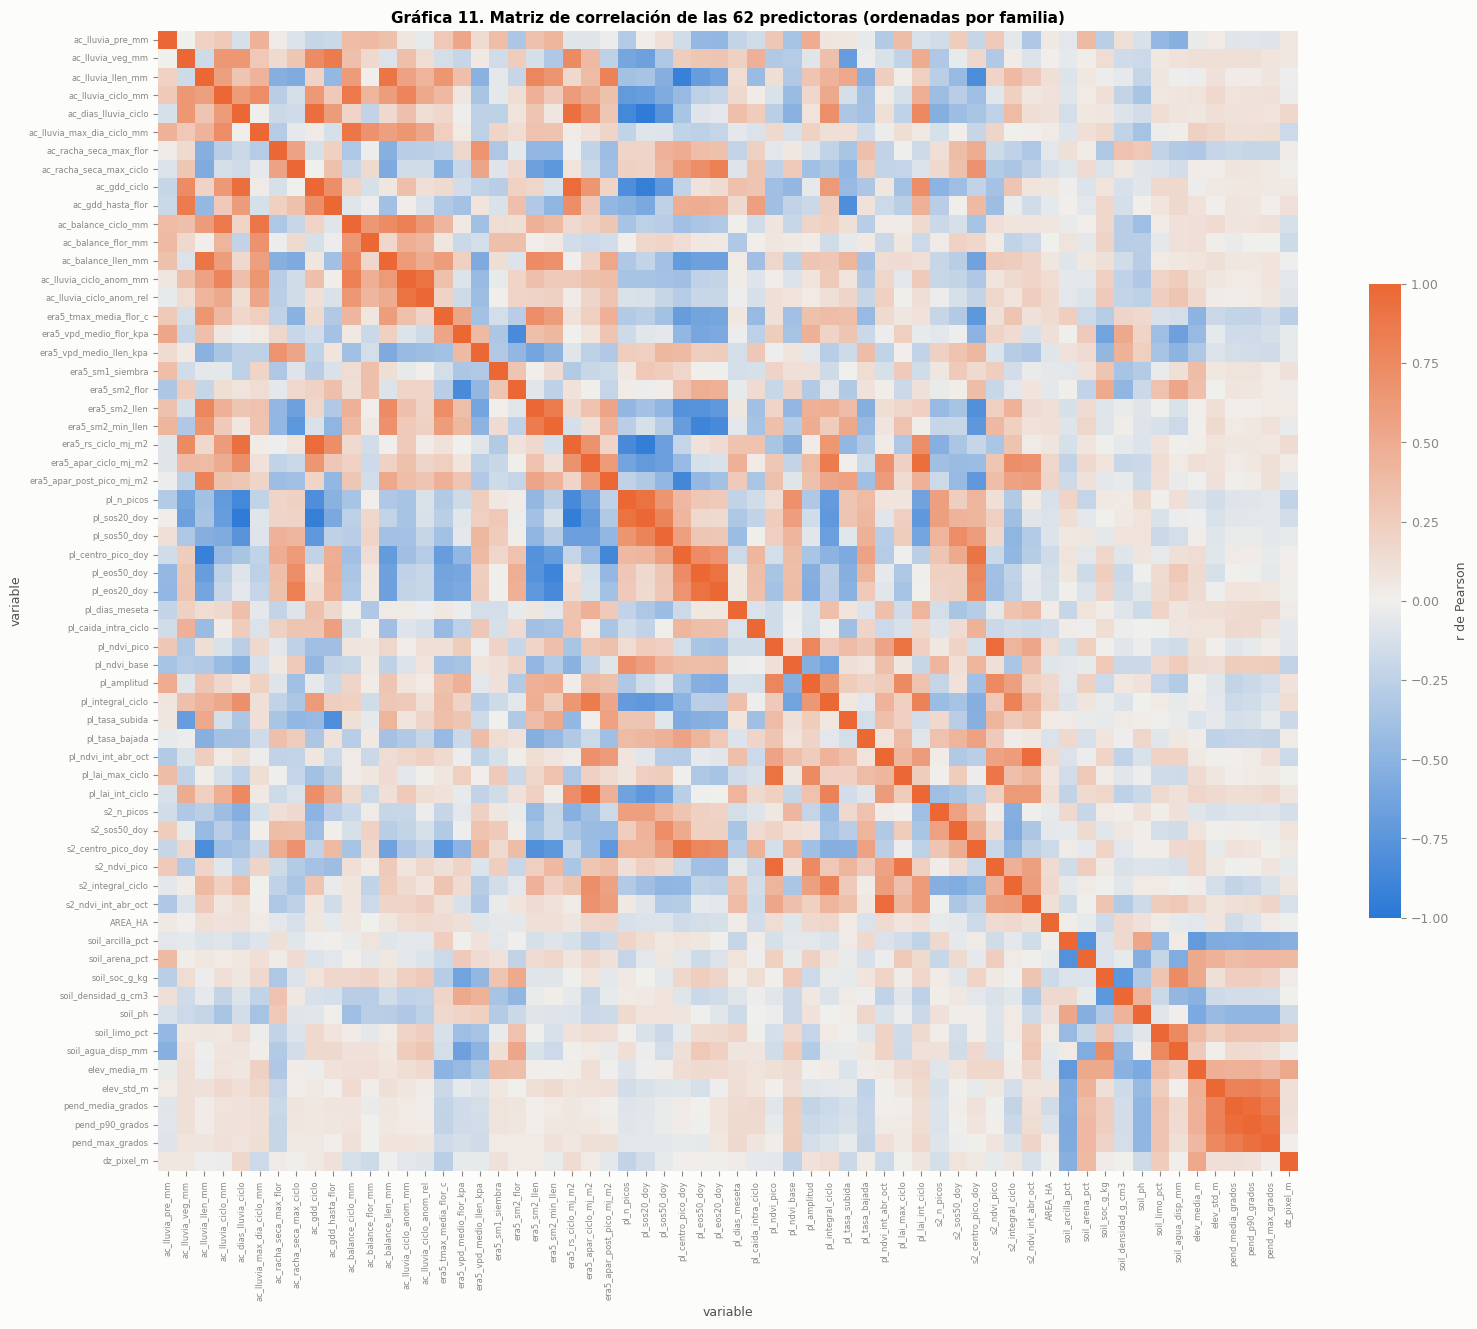

In [31]:
# Gráfica 11. de la matriz de correlación de las variables predictoras (ordenadas por familia)
corr_fam = corr_mat.loc[orden_fam, orden_fam]
fig, ax = plt.subplots(figsize=(16, 14))
sns.heatmap(corr_fam, cmap=CMAP_DIV, vmin=-1, vmax=1, center=0, square=True,
            xticklabels=True, yticklabels=True, cbar_kws={"shrink": 0.5, "label": "r de Pearson"}, ax=ax)
ax.tick_params(labelsize=6)
ax.set_title(f"Gráfica 11. Matriz de correlación de las {len(predictoras)} predictoras (ordenadas por familia)")
plt.tight_layout(); plt.show()

- - -

## 8. Consistencia entre sensores para la misma métrica fenológica (Planet `pl_` vs. Sentinel-2 `s2_`)

> **[Texto]** **¿Podemos confiar indistintamente en Sentinel-2 y PlanetScope para estas métricas, o existen sesgos sistemáticos o discrepancias notables entre ambos sensores?**

Concordancia Planet vs. Sentinel-2:
                   r_pearson  dif_media (pl - s2)  dif_abs_media
SOS50 (día)            0.724                3.670          7.091
Pico (día)             0.912                0.523          4.310
EOS50 (día)            0.983                2.056          2.543
NDVI pico              0.962                0.094          0.094
Integral ciclo         0.804                2.065          4.461
NDVI int. abr-oct      0.967               17.831         17.831

Parcelas con fenología discrepante (bandera del ETL): 29


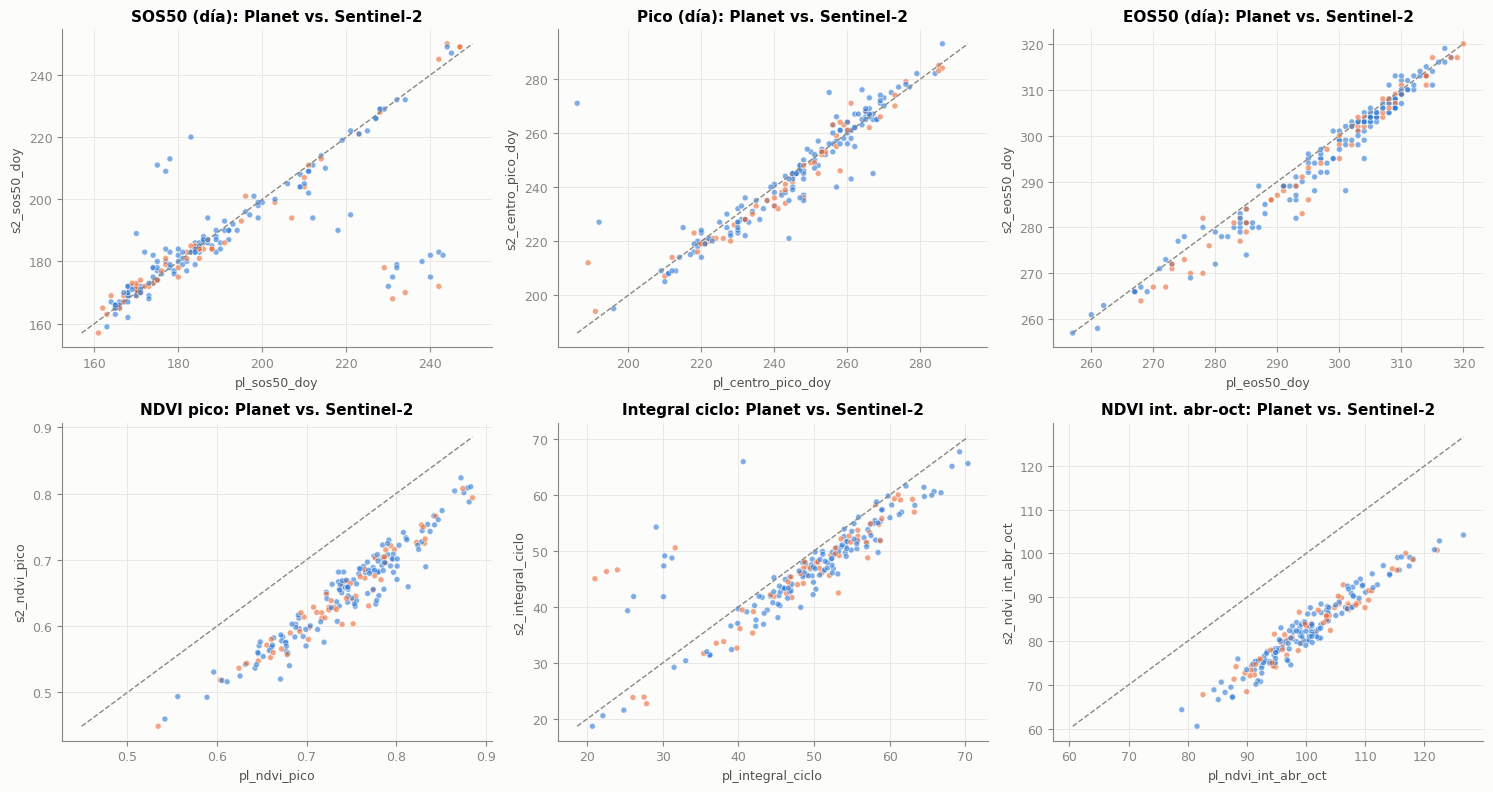

In [32]:
# Consistencia entre sensores para la misma métrica fenológica (Planet pl_ vs. Sentinel-2 s2_)
pares_sens = {"SOS50 (día)": ("pl_sos50_doy", "s2_sos50_doy"),
              "Pico (día)": ("pl_centro_pico_doy", "s2_centro_pico_doy"),
              "EOS50 (día)": ("pl_eos50_doy", "s2_eos50_doy"),
              "NDVI pico": ("pl_ndvi_pico", "s2_ndvi_pico"),
              "Integral ciclo": ("pl_integral_ciclo", "s2_integral_ciclo"),
              "NDVI int. abr-oct": ("pl_ndvi_int_abr_oct", "s2_ndvi_int_abr_oct")}
cons = pd.DataFrame({k: {"r_pearson": df[a].corr(df[b]), "dif_media (pl - s2)": (df[a] - df[b]).mean(),
                         "dif_abs_media": (df[a] - df[b]).abs().mean()}
                     for k, (a, b) in pares_sens.items()}).T
print("Concordancia Planet vs. Sentinel-2:")
print(cons.round(3))
print("\nParcelas con fenología discrepante (bandera del ETL):", int(df["diag_fenologia_discrepante"].sum()))

# 12. Gráficas de dispersión de las métricas fenológicas entre sensores
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (k, (a, b)) in zip(axes.ravel(), pares_sens.items()):
    ax.scatter(df[a], df[b], s=18, alpha=0.6, c=df["CONJUNTO"].map(COLOR_CONJ), edgecolor="#fcfcfb", lw=0.6)
    lim = [min(df[a].min(), df[b].min()), max(df[a].max(), df[b].max())]
    ax.plot(lim, lim, color=GRIS_EJE, ls="--", lw=1)
    ax.set_title(f"{k}: Planet vs. Sentinel-2"); ax.set_xlabel(a); ax.set_ylabel(b)
plt.tight_layout(); 
plt.show()

#### [Interpretación]

**Fechas del ciclo fenológico (días del año, DOY)**

> **[Estadística]**
>
> | Métrica | Correlación ($r$) | Error / sesgo | Lectura |
> |---|---|---|---|
> | SOS50 (inicio de temporada al 50 %) | 0.724 | Diferencia absoluta media ≈ 7.1 días | La menor correlación de las fechas |
> | Pico (día del máximo verdor) | 0.912 | Error absoluto medio 4.31 días; sesgo medio 0.523 días | Concordancia muy sólida |
> | EOS50 (fin de temporada al 50 %) | 0.983 | MAE = 2.54 días | La mayor consistencia temporal |

- **SOS50:** en el gráfico de dispersión se observa un grupo atípico de puntos en la zona inferior derecha (Planet ≈ 230–240, Sentinel-2 ≈ 180), que arrastra la correlación a la baja. Excluyendo estas anomalías, la concordancia general es alta en la línea 1:1.
- **Pico:** la mayoría de las observaciones se alinean linealmente sobre la diagonal 1:1.
- **EOS50:** los datos se adhieren estrechamente a la línea de identidad, lo que indica que ambos satélites detectan la senescencia con un margen de error menor a 3 días.

**Magnitudes e integrales de índices de vegetación (NDVI)**

- **NDVI pico:** tiene una correlación lineal excelente ($r = 0.962$). Sin embargo, la diferencia media (0.094) y la inspección visual revelan un sesgo sistemático positivo constante hacia PlanetScope: los puntos caen sistemáticamente por debajo de la línea 1:1. PlanetScope registra valores de NDVI pico aproximadamente 0.10 unidades por encima de Sentinel-2.
- **Integral del ciclo:** muestra buena correlación ($r = 0.804$) con una diferencia absoluta media de 4.46 unidades. Al igual que en el NDVI pico, PlanetScope tiende a registrar valores ligeramente mayores para la mayoría de las parcelas.
- **NDVI integral abr-oct:** aunque la correlación es muy elevada ($r = 0.967$), existe un desfase escalar masivo ($\text{dif\_media} = 17.831$). Esto se debe a la acumulación del sesgo de NDVI superior de PlanetScope a lo largo del periodo de integración (abril a octubre).

**Posibles causas de las diferencias**

- **Resolución espacial y mezcla de píxeles (*pixel unmixing*):** PlanetScope (3 m) captura menor mezcla espectral con suelo desnudo o bordes de parcelas que Sentinel-2 (10 m en bandas VIS/NIR). Esto explica por qué PlanetScope registra valores absolutos de NDVI más altos (efecto de atenuación por píxel mixto en Sentinel-2).
- **Calibración radiométrica y anchura de bandas:** Sentinel-2 cuenta con bandas espectrales más estrechas y mejor calibración atmosférica e inter-sensor que PlanetScope (constelación de CubeSats).
- **Bandera de fenología discrepante (29 parcelas):** se identificaron 29 parcelas atípicas. Estas explican las dispersiones aisladas observadas en los gráficos de dispersión de SOS50 e integral del ciclo, probablemente asociadas a persistencia de nubes, coberturas heterogéneas o fallas en el ajuste de la curva fenológica.

**[Bibliografía]**
- Zeng, L., Wardlow, B. D., Xiang, D., Hu, S., & Li, D. (2020). A review of vegetation phenological metrics extraction using time-series satellite imagery. *Remote Sensing, 12*(8), Artículo 1349. https://doi.org/10.3390/rs12081349
- Bolton, D. K., Gray, J. M., Melaas, E. K., Moon, M., Eklundh, L., & Friedl, M. A. (2020). Continental-scale land surface phenology from Harmonized Landsat Sentinel-2 including dynamic sampling of high spatial resolution PlanetScope imagery. *Remote Sensing of Environment, 240*, Artículo 111685. https://doi.org/10.1016/j.rse.2020.111685

- - -

## 9. Selección *greedy* de variables

> **[Metodología]** La **selección *greedy*** (voraz) es un método algorítmico iterativo para la selección de variables. Toma la mejor decisión óptima local en cada paso con la esperanza de encontrar un óptimo global. Agrega o depura variables una por una de acuerdo con un criterio estadístico y no evalúa todas las combinaciones posibles de variables.

> **[Decisión de modelado]** Se usa un umbral de **$|r| > 0.90$**, ya que elimina las 17 parejas con redundancia severa y reduce el espacio a 51 variables.

**[Bibliografía]**
- Guyon, I., & Elisseeff, A. (2003). An introduction to variable and feature selection. *Journal of Machine Learning Research, 3*, 1157–1182.

In [33]:
# Selección greedy: eliminar variables redundantes (|r| > 0.90) conservando la más correlacionada con el objetivo
orden = mi_tabla_BH.index.tolist()  # ordenadas por |spearman| con el rendimiento
seleccion = []
eliminadas_por = {} 

for c in orden:
    redundante = False
    for s in seleccion:
        if abs(corr_mat.loc[c, s]) > 0.90:
            eliminadas_por[c] = s  
            redundante = True
            break  
            
    if not redundante:
        seleccion.append(c)

print(f"Variables tras filtrar redundancia (|r| ≤ 0.90): {len(seleccion)}")
print(seleccion[:30])

# Filtra la tabla original para conservar solo las 51 seleccionadas
tabla_seleccion = mi_tabla_BH.loc[seleccion].copy()

# Agrega una columna de posición
tabla_seleccion.insert(0, "Ranking", range(1, len(tabla_seleccion) + 1))

print(tabla_seleccion)

print(f"\nVariables descartadas por redundancia (|r| > 0.90): {len(eliminadas_por)}")
for descartada, causante in eliminadas_por.items():
    print(f" - '{descartada}' fue descartada por ser redundante con '{causante}'")

Variables tras filtrar redundancia (|r| ≤ 0.90): 51
['era5_vpd_medio_flor_kpa', 'ac_lluvia_pre_mm', 'era5_sm2_flor', 'soil_agua_disp_mm', 'soil_soc_g_kg', 'pl_eos50_doy', 'soil_densidad_g_cm3', 'ac_gdd_ciclo', 'pl_amplitud', 'soil_limo_pct', 'era5_vpd_medio_llen_kpa', 'pl_ndvi_base', 's2_ndvi_int_abr_oct', 'ac_gdd_hasta_flor', 'era5_sm2_min_llen', 'elev_media_m', 'pl_dias_meseta', 'era5_tmax_media_flor_c', 'AREA_HA', 'pl_lai_int_ciclo', 'pend_max_grados', 'pend_media_grados', 'pl_lai_max_ciclo', 'pl_centro_pico_doy', 'pl_tasa_subida', 'soil_arena_pct', 's2_sos50_doy', 'pl_caida_intra_ciclo', 'pl_sos50_doy', 'era5_sm2_llen']
                            Ranking   pearson  spearman               familia  |spearman|       p_valor   p_valor_fdr  signif_fdr
era5_vpd_medio_flor_kpa           1 -0.661084 -0.640712             ERA5-Land    0.640712  2.603810e-17  1.614362e-15        True
ac_lluvia_pre_mm                  2 -0.596064 -0.578335             Agroclima    0.578335  1.100234e-13  3.4

#### [Interpretación]

Variables descartadas y la variable con la que son redundantes:

| Variable descartada | Conservada | Justificación |
|---|---|---|
| `pl_eos20_doy` | `pl_eos50_doy` | De acuerdo con la gráfica 7, el final de la temporada está muy sincronizado; mantener `eos50` (la mitad de la senescencia) es más robusto. |
| `ac_dias_lluvia_ciclo`, `pl_sos20_doy`, `era5_rs_ciclo_mj_m2` | `ac_gdd_ciclo` | La acumulación térmica "absorbió" a tres variables distintas (días de lluvia, inicio de temporada y radiación solar). Se confirma que, en términos agronómicos, la temperatura y la radiación determinan el reloj fenológico de la planta. |
| `pend_p90_grados` | `pend_max_grados` | Ambas miden la inclinación extrema del terreno. |
| `pl_ndvi_int_abr_oct` | `s2_ndvi_int_abr_oct` | Ambas integrales están casi duplicadas ($r = 0.9667$). El algoritmo conserva la de mayor $\vert\rho\vert$ con el rendimiento, que resultó ser la de Sentinel-2. |
| `pl_ndvi_pico` | `pl_lai_max_ciclo` | El índice de área foliar (LAI) se deriva de los índices de vegetación; es normal que el pico de verdor (NDVI) sea idéntico al pico de área foliar. |
| `s2_centro_pico_doy` | `pl_centro_pico_doy` | Se prefiere el dato de Planet sobre el de Sentinel-2 para el pico fenológico. |
| `ac_lluvia_llen_mm` | `pl_centro_pico_doy` | Supera $\vert r\vert > 0.90$ con el día del pico, que tiene mayor $\vert\rho\vert$ con el rendimiento. Es plausible agronómicamente: el momento del pico fija la ventana de llenado en la que se acumula esa lluvia. |
| `era5_apar_ciclo_mj_m2` | `pl_lai_int_ciclo` | La radiación fotosintéticamente activa absorbida (APAR) depende directamente de cuánta hoja (LAI) tiene el cultivo para capturar luz. |
| `ac_lluvia_ciclo_anom_mm` | `ac_lluvia_ciclo_anom_rel` | Son la misma anomalía de lluvia, una en milímetros y otra en porcentaje. |

> **[Decisión de modelado]** El filtro *greedy* conservó `s2_ndvi_int_abr_oct` y descartó `pl_ndvi_int_abr_oct`. Para el modelado se decidió lo contrario: conservar la integral de **Planet** (`pl_ndvi_int_abr_oct`), por su resolución de 3 m y por coherencia con el resto de la fenología que se toma de Planet (`pl_centro_pico_doy`, `pl_eos50_doy`). Por eso las recomendaciones del apartado 13 eliminan `s2_ndvi_int_abr_oct`.

- - -

## 10. Análisis de componentes principales (PCA)

> **[Metodología]** El análisis de componentes principales es una técnica exploratoria de la estructura de los datos. No supone especificar un modelo probabilístico en las variables medibles.
>
> Los principales objetivos del PCA son:
> - Identificar las nuevas variables, llamadas **componentes principales**, así como su significado.
> - Reducir la dimensionalidad de los datos de origen.

**[Bibliografía]**
- Ipiña, S. L., & Durand, A. I. (2008). *Inferencia estadística y análisis de datos*. Pearson.
- Jolliffe, I. T., & Cadima, J. (2016). Principal component analysis: A review and recent developments. *Philosophical Transactions of the Royal Society A, 374*(2065), 20150202. https://doi.org/10.1098/rsta.2015.0202

Componentes para 80% de varianza: 8
Componentes para 90% de varianza: 14
Componentes para 95% de varianza: 19
Componentes para 99% de varianza: 31


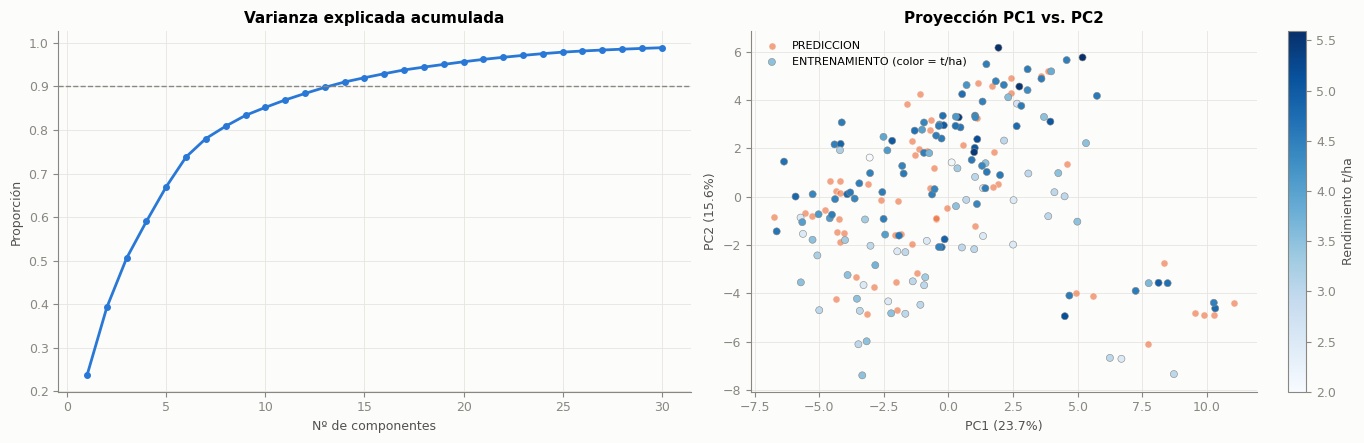

Correlación de Spearman de las primeras 10 PC con el rendimiento:
PC1     0.114
PC2     0.431
PC3     0.363
PC4     0.214
PC5    -0.314
PC6    -0.195
PC7     0.170
PC8    -0.112
PC9    -0.106
PC10    0.047
dtype: float64
Top 5 variables que definen PC2
ac_gdd_hasta_flor: 0.2803
ac_lluvia_veg_mm: 0.2598
ac_gdd_ciclo: 0.2575
era5_rs_ciclo_mj_m2: 0.2497
ac_dias_lluvia_ciclo: 0.2221
Top 5 variables que definen PC3
elev_media_m: 0.2667
soil_soc_g_kg: 0.2410
soil_ph: -0.2253
soil_densidad_g_cm3: -0.2220
pend_p90_grados: 0.2212
Top 5 variables que definen PC5
soil_arena_pct: 0.3721
soil_agua_disp_mm: -0.2790
soil_arcilla_pct: -0.2669
ac_lluvia_pre_mm: 0.2437
elev_std_m: 0.2248


In [34]:
# PCA para reducción de dimensionalidad 
X = StandardScaler().fit_transform(df[predictoras])
pca = PCA().fit(X)
var_acum = np.cumsum(pca.explained_variance_ratio_)
for u in [0.80, 0.90, 0.95, 0.99]:
    print(f"Componentes para {u:.0%} de varianza: {np.argmax(var_acum >= u) + 1}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(range(1, 31), var_acum[:30], marker="o", color=AZUL, lw=2, ms=4)
axes[0].axhline(0.9, color=GRIS_EJE, ls="--", lw=1)
axes[0].set_title("Varianza explicada acumulada"); axes[0].set_xlabel("Nº de componentes"); axes[0].set_ylabel("Proporción")

Z = pca.transform(X)[:, :2]
es_train = (df["CONJUNTO"] == "ENTRENAMIENTO").values
axes[1].scatter(Z[~es_train, 0], Z[~es_train, 1], s=26, color=NARANJA, alpha=0.6,
                edgecolor="#fcfcfb", lw=0.6, label="PREDICCION")
sc = axes[1].scatter(Z[es_train, 0], Z[es_train, 1], s=26, c=y, cmap="Blues",
                     edgecolor=GRIS_EJE, lw=0.4, label="ENTRENAMIENTO (color = t/ha)")
plt.colorbar(sc, ax=axes[1], label="Rendimiento t/ha")
axes[1].set_title("Proyección PC1 vs. PC2"); axes[1].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
axes[1].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})"); axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); 
plt.show()

pcs_train = pd.DataFrame(pca.transform(X)[es_train, :10], columns=[f"PC{i}" for i in range(1, 11)])
print("Correlación de Spearman de las primeras 10 PC con el rendimiento:")
print(pcs_train.corrwith(y.reset_index(drop=True), method="spearman").round(3))

# Crear un DataFrame con las cargas de cada variable en cada componente
cargas_pca = pd.DataFrame(
    pca.components_, 
    columns=predictoras, 
    index=[f"PC{i}" for i in range(1, pca.n_components_ + 1)]
)

# Función para ver las 5 variables más importantes de una componente específica
def ver_top_cargas(pc_name, top_n=5):
    cargas = cargas_pca.loc[pc_name].abs().sort_values(ascending=False)
    print(f"Top {top_n} variables que definen {pc_name}")
    for var in cargas.head(top_n).index:
        peso_real = cargas_pca.loc[pc_name, var]
        print(f"{var}: {peso_real:.4f}")

ver_top_cargas("PC2")
ver_top_cargas("PC3")
ver_top_cargas("PC5")

#### [Interpretación]

**Componentes más predictivos: PC2 ($r_s = 0.431$) y PC3 ($r_s = 0.363$)**

- PC1 no es la componente con mayor capacidad explicativa sobre el rendimiento, a pesar de concentrar la mayor varianza individual (23.7 %).
- PC2 presenta la correlación positiva más fuerte con el rendimiento, lo que coincide con el patrón observado en el gráfico 2D, donde los valores altos de t/ha se desplazaban verticalmente hacia la parte superior.
- PC3 muestra la segunda correlación más alta, lo que indica que la tercera dimensión ortogonal rescata una porción importante de la varianza agronómica y climática ligada al rendimiento.

**Relación inversa relevante: PC5 ($r_s = -0.314$)**

- Presenta una correlación negativa moderada significativa. Esto implica que los factores o variables originales cargados negativamente en esta componente tienen un efecto directo favorable sobre el rendimiento (o viceversa).

**Aportes secundarios: PC4 ($r_s = 0.214$), PC6 ($r_s = -0.195$) y PC7 ($r_s = 0.170$)**

- Mantienen un nivel de asociación lineal o monótona moderado-bajo que añade valor descriptivo al modelo.

**Baja asociación directa: PC1 ($r_s = 0.114$) y PC8 a PC10 ($\vert r_s\vert \le 0.112$)**

- PC1 explica la mayor variabilidad global entre las variables predictoras (por ejemplo, variaciones generales de suelo o clima), pero esa variabilidad no está fuertemente alineada con el rendimiento agrícola.
- PC10 ($r_s = 0.047$) prácticamente no guarda relación monótona con la variable respuesta.

> **[Conclusión parcial]** A partir del análisis de componentes se puede inferir que el rendimiento está impulsado por dimensiones ortogonales específicas (PC2 y PC3) que están latentes en las observaciones espaciales y climáticas.

- - -

## 11. Comparabilidad entre entrenamiento y predicción (*data shift*)

> **[Texto]** Se evalúa cada variable predictora para conocer si su distribución cambió entre el conjunto de entrenamiento y el de predicción. Se usan dos enfoques (ver 2.1.F):
>
> - **Análisis univariado:** prueba de Kolmogorov-Smirnov (KS), una prueba por variable.
> - **Análisis multivariado:** **validación adversarial**, un enfoque de *machine learning* que evalúa todas las variables predictoras en conjunto.

In [35]:
# Prueba de Kolmogorov-Smirnov para comparar la distribución de las variables predictoras entre entrenamiento y predicción
ks = pd.DataFrame({c: stats.ks_2samp(train[c], pred[c]) for c in predictoras}, index=["KS", "p_valor"]).T
ks = ks.sort_values("p_valor")
print(f"Variables con distribución distinta (KS, p < 0.05): {(ks['p_valor'] < 0.05).sum()} de {len(predictoras)}")
print(ks.head(10).round(4))

# Validación adversarial: ¿se puede distinguir entrenamiento de predicción?
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
rf_adv = RandomForestClassifier(n_estimators=300, random_state=42, class_weight="balanced")
auc = cross_val_score(rf_adv, df[predictoras], es_train.astype(int), cv=5, scoring="roc_auc")
print(f"\nAUC adversarial (5-fold): {auc.mean():.3f} ± {auc.std():.3f}  (≈0.5 = conjuntos indistinguibles)")

Variables con distribución distinta (KS, p < 0.05): 0 de 62
                             KS  p_valor
pl_tasa_bajada           0.1968   0.0700
soil_limo_pct            0.1855   0.0988
pl_tasa_subida           0.1805   0.1155
era5_vpd_medio_llen_kpa  0.1749   0.1397
era5_sm2_llen            0.1705   0.1579
s2_sos50_doy             0.1701   0.1607
ac_lluvia_ciclo_anom_mm  0.1683   0.1675
ac_balance_llen_mm       0.1678   0.1716
ac_lluvia_ciclo_mm       0.1611   0.2041
pl_ndvi_int_abr_oct      0.1605   0.2099

AUC adversarial (5-fold): 0.461 ± 0.072  (≈0.5 = conjuntos indistinguibles)


#### [Interpretación]

> **[Estadística]**
>
> | Análisis | Resultado | Lectura |
> |---|---|---|
> | Univariado (KS) | 0 de 62 variables con distribución distinta | Ninguna variable predictora presenta diferencias estadísticamente significativas ($p < 0.05$) entre ambos conjuntos. |
> | Multivariado (clasificador adversarial) | AUC = 0.461 (± 0.072) | Valor cercano a 0.5: el Random Forest fue incapaz de encontrar patrones ocultos o combinaciones de variables que permitieran separar las filas de entrenamiento de las de predicción. |

Se puede inferir que, para el clasificador, ambos conjuntos son indistinguibles.

- - -

## 12. Línea base rápida de importancia de variables (Random Forest)

> **[Texto]** Se realiza una prueba exploratoria con Random Forest sin ninguna restricción, con validación cruzada aleatoria (`KFold`) y agrupada por municipio (`GroupKFold`). Ver 2.1.G.

RF 5-fold aleatorio  -> R²: 0.541 | MAE: 0.433 | RMSE: 0.575 t/ha
RF 5-fold por municipio -> R²: -0.354 | MAE: 0.870 | RMSE: 0.987 t/ha
Línea base (predecir la media) -> MAE: 0.749 t/ha


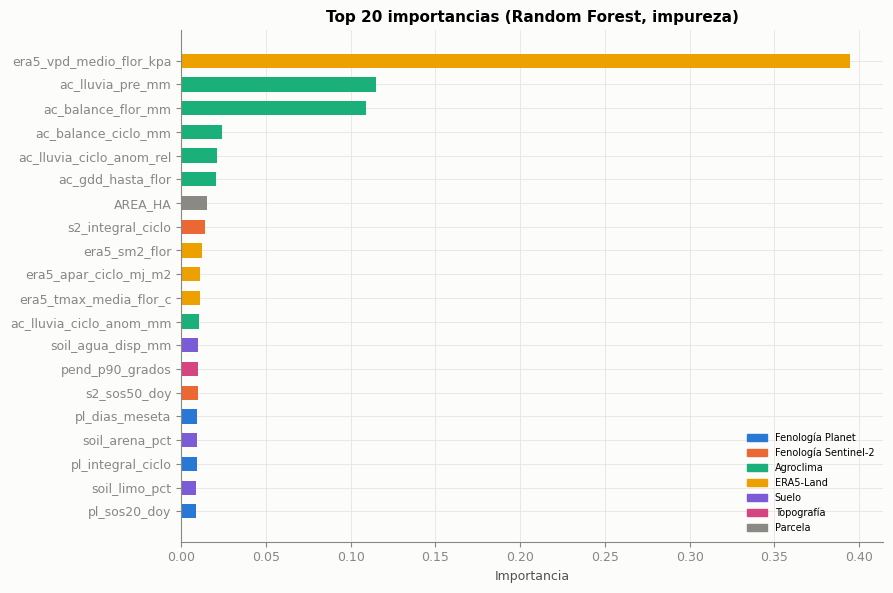

In [36]:
# Referencia exploratoria, nos indica qué variable aportan señal no lineal
from sklearn.model_selection import KFold, cross_val_predict
rf = RandomForestRegressor(n_estimators=500, min_samples_leaf=3, random_state=42, n_jobs=-1)
cv = KFold(n_splits=5, shuffle=True, random_state=42)
y_hat = cross_val_predict(rf, train[predictoras], y, cv=cv)
print(f"RF 5-fold aleatorio  -> R²: {r2_score(y, y_hat):.3f} | MAE: {mean_absolute_error(y, y_hat):.3f} | "
      f"RMSE: {np.sqrt(mean_squared_error(y, y_hat)):.3f} t/ha")

# Validación agrupada por municipio: mide si el modelo generaliza a zonas que no vio
y_hat_mun = cross_val_predict(rf, train[predictoras], y, cv=GroupKFold(n_splits=5), groups=train["municipio"])
print(f"RF 5-fold por municipio -> R²: {r2_score(y, y_hat_mun):.3f} | MAE: {mean_absolute_error(y, y_hat_mun):.3f} | "
      f"RMSE: {np.sqrt(mean_squared_error(y, y_hat_mun)):.3f} t/ha")
print(f"Línea base (predecir la media) -> MAE: {mean_absolute_error(y, np.full_like(y, y.mean())):.3f} t/ha")

rf.fit(train[predictoras], y)
imp = pd.Series(rf.feature_importances_, index=predictoras).sort_values(ascending=False).head(20)
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(imp.index[::-1], imp.values[::-1], color=[COLOR_FAM[familia_de(c)] for c in imp.index[::-1]], height=0.6)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=v) for v in COLOR_FAM.values()], labels=list(COLOR_FAM),
          frameon=False, fontsize=7, loc="lower right")
ax.set_title("Top 20 importancias (Random Forest, impureza)"); ax.set_xlabel("Importancia")
plt.tight_layout(); 
plt.show()

#### [Interpretación]

**Falso optimismo en la validación aleatoria**

Al utilizar `KFold` aleatorio parece que el modelo funciona bien (R² de 0.541 y MAE de 0.433 t/ha). Sin embargo, al ser datos espaciales, las observaciones cercanas son muy similares (hay autocorrelación espacial), y el modelo simplemente memorizó los patrones locales.

**Validación agrupada por municipio**

> **[Estadística]**
>
> | Validación | R² | MAE (t/ha) |
> |---|---|---|
> | `KFold` aleatorio | 0.541 | 0.433 |
> | `GroupKFold` por municipio | −0.354 | 0.870 |
> | Línea base (predecir la media) | — | 0.749 |

Con `GroupKFold` por municipio, el R² negativo indica que el modelo es peor que predecir el promedio global: su MAE (0.870 t/ha) es mayor que el de la línea base (0.749 t/ha).

El modelo de Random Forest sufre un **sobreajuste (*overfitting*) espacial severo**. Se puede inferir que "aprendió" a predecir el rendimiento basándose en *dónde* está la parcela, pero no usa las relaciones agronómicas para predecir en un municipio que nunca ha visto.

**Importancia de variables**

- La variable `era5_vpd_medio_flor_kpa` (déficit de presión de vapor en floración) tiene mayor relevancia que el resto (importancia casi de 0.40).
- Las variables climáticas tienen mayor relevancia que las satelitales: las 6 variables principales son agroclimáticas (nivel macro) y una de ERA5-Land. Las variables a nivel micro (tamaño de parcela, fenología Sentinel-2/Planet y características del suelo) tienen una importancia baja en comparación.

> **[Decisión de modelado]** En este ensayo, el Random Forest está usando el clima (especialmente el VPD) como un "identificador geográfico". Dado que el clima es idéntico o muy similar para todas las parcelas dentro de un mismo municipio pero varía entre municipios, el modelo usa estas variables macro para adivinar el municipio y asignar el rendimiento promedio de esa zona que memorizó durante el entrenamiento. Ignora las condiciones reales (satelitales y de suelo) de cada parcela individual.

- - -

## 13. Conclusiones del EDA

### Estructura y calidad

- 197 parcelas × 98 columnas: 138 de **entrenamiento** (70.1 %) y 59 de **predicción** (29.9 %), en 9 municipios de Puebla, Tlaxcala e Hidalgo. Chignahuapan concentra 100 parcelas.
- Tras quitar metadatos, columnas ETL, banderas `diag_*` y variables podadas quedan **62 predictoras numéricas** organizadas en 7 familias (Agroclima 15, ERA5 10, Fenología Planet 17, Fenología Sentinel-2 6, Suelo 7, Topografía 6, Parcela 1).
- Las variables predictoras no tienen faltantes, infinitos ni duplicados. Solo faltan `RENDIMIENTO_T_HA`, `diag_y_redondo*` y `diag_y_resolución*`, exactamente en el conjunto de predicción.
- `pl_n_picos` y `s2_n_picos` reportan datos similares (se elige la que mejores métricas tenga).
- El calendario fenológico es coherente (SOS20 ≤ SOS50 ≤ pico ≤ EOS50 ≤ EOS20 en las 197 parcelas). `pl_duracion_dias` es exactamente EOS20 − SOS20, así que es redundante.

### Variable objetivo

- Media 3.96 t/ha, mediana 4.34, rango 2.0–5.59. No es normal (Shapiro $p < 0.001$) y no tiene atípicos según IQR.
- Es **bimodal**: grupo bajo (~3.1 t/ha, n = 58) y grupo alto (~4.6 t/ha, n = 80), con corte cerca de 3.83 t/ha.
- La resolución del reporte separa casi perfectamente los grupos: 44 de los 58 bajos se reportaron a 0.5 t/ha, y 73 de los 80 altos a 0.01 t/ha. Hay **ruido de etiqueta** por la forma de registro.
- El rendimiento depende fuertemente del **municipio** (≈ 4.5 t/ha en Chignahuapan, Almoloya y Cuautepec vs. ≈ 3.0 en Calpulalpan y Singuilucan). Zona, forma de registro y grupo de rendimiento están **confundidos**.

### Relación con los predictores

- La señal es **fuerte en apariencia**: 16 variables siguen siendo significativas tras Bonferroni. Las principales son `era5_vpd_medio_flor_kpa` (ρ = −0.64), `ac_lluvia_pre_mm` (−0.58), `era5_sm2_flor` (+0.54), `soil_agua_disp_mm` (+0.51), `soil_soc_g_kg` (+0.46) y el fin de ciclo `pl_eos50_doy` (+0.44).
- Tras la prueba de Benjamini-Hochberg aumentan las variables predictoras significativas (de 16 a 34) con solo 3 falsos positivos.
- La lectura agronómica es coherente: menos déficit de presión de vapor y más humedad del suelo en floración, suelos con más agua disponible y carbono, y ciclos más largos se asocian con más rendimiento.
- Pero clima y suelo cambian sobre todo **entre zonas**, así que buena parte de esta señal puede ser el efecto del municipio (y de su forma de registro) y no un efecto dentro de cada zona.
- El área tiene una relación débil y negativa (Spearman −0.25).

### Redundancia

- 6 pares con |r| > 0.95 y 17 con |r| > 0.90 (por ejemplo `pl_ndvi_pico` ≈ `pl_ndvi_max_abr_oct`, `pl_ndvi_int_abr_oct` ≈ `pl_ndvi_media_abr_oct`, `AREA_HA` ≈ `topo_cobertura_pix`, elevaciones media/mín./máx., y `pl_duracion_dias` con GDD, ETo y radiación del ciclo).
- Planet y Sentinel-2 coinciden bien en EOS50 (r = 0.98) y NDVI pico (r = 0.96, aunque Planet da ≈ 0.09 más de NDVI), y peor en SOS50 (r = 0.72).
- El filtro *greedy* con |r| ≤ 0.90 deja **51 de 62** variables.
- El PCA reúne el 90 % de la varianza en **14 componentes**; la PC2 es la más correlacionada con el rendimiento (ρ ≈ 0.43).

### Entrenamiento vs. predicción

- Ninguna variable difiere entre conjuntos (KS $p > 0.05$) y la AUC adversarial es ≈ 0.46: los conjuntos son **comparables** y el split 70/30 es representativo, también por municipio.

- - -

### Línea base con ensayo de Random Forest

- Un Random Forest con CV 5-fold aleatoria da R² ≈ 0.55 y MAE ≈ 0.43 t/ha (vs. 0.75 al predecir la media). `era5_vpd_medio_flor_kpa` acapara ≈ 39 % de la importancia.
- Con CV **agrupada por municipio** el R² cae a ≈ −0.31 y el MAE sube a ≈ 0.86 t/ha, peor que predecir la media: el modelo **no generaliza a municipios que no vio** y aprende sobre todo la zona.

### Recomendaciones para el modelado en Random Forest

> **[Texto]** Derivado del análisis del EDA, se consideran las siguientes recomendaciones para un modelo en Random Forest.

1. Como las 59 parcelas de predicción están en los mismos municipios que el entrenamiento, la CV aleatoria es válida para este split.
2. Conservar las variables de identidad (`id_poligono`, `municipio`, `estado`, `conjunto`, `clima_pixel_id`) en la tabla de preprocesamiento solo para trazabilidad y para formar los grupos de validación. **No entran a la matriz de predictoras $X$** (en particular, `municipio` se excluye, ver 2.3.3).
3. Separar el efecto de zona: incluir una nueva variable `grupo_rend` como variable estratificadora de 5 *splits*.
4. Tratar el ruido de etiqueta: incluir `diag_y_resolucion` como ponderador de error (utilizar `sample_weight` en el método `.fit()`).
5. Descartar las variables de diagnóstico `diag_fenologia_discrepante`, `diag_topo_nodata`, `diag_sin_ciclo`, `diag_ciclo_ambiguo`, `diag_s2_sin_ciclo` y `diag_era5_vecino` como variables de control para Random Forest.
6. Incluir `diag_topo_pocos_pix` como *feature* (columna binaria, es decir, 1 y 0) en la matriz de características predictoras ($X$) al momento de entrenar.
7. Eliminar de las variables predictoras las redundancias exactas: `pl_eos20_doy`, `ac_dias_lluvia_ciclo`, `pl_sos20_doy`, `era5_rs_ciclo_mj_m2`, `pend_p90_grados`, `s2_ndvi_int_abr_oct` (se conserva su equivalente de Planet, ver apartado 9), `pl_ndvi_pico`, `s2_centro_pico_doy`, `ac_lluvia_llen_mm`, `era5_apar_ciclo_mj_m2`, `ac_lluvia_ciclo_anom_mm`.
8. Columnas a incluir en el preprocesamiento:

| Grupo | Columnas |
|---|---|
| **Metadatos** | `id_poligono`, `municipio`, `estado`, `conjunto`, `clima_pixel_id` |
| **Variable objetivo** | `rendimiento_t_ha` |
| **Variables predictoras** | `era5_vpd_medio_flor_kpa`, `ac_lluvia_pre_mm`, `era5_sm2_flor`, `soil_agua_disp_mm`, `soil_soc_g_kg`, `pl_eos50_doy`, `soil_densidad_g_cm3`, `ac_gdd_ciclo`, `pl_amplitud`, `soil_limo_pct`, `era5_vpd_medio_llen_kpa`, `pl_ndvi_base`, `pl_ndvi_int_abr_oct`, `ac_gdd_hasta_flor`, `era5_sm2_min_llen`, `elev_media_m`, `pl_dias_meseta`, `era5_tmax_media_flor_c`, `AREA_HA`, `pl_lai_int_ciclo`, `pend_max_grados`, `pend_media_grados`, `pl_lai_max_ciclo`, `pl_centro_pico_doy`, `pl_tasa_subida`, `soil_arena_pct`, `s2_sos50_doy`, `pl_caida_intra_ciclo`, `pl_sos50_doy`, `era5_sm2_llen`, `ac_lluvia_veg_mm`, `era5_sm1_siembra`, `ac_racha_seca_max_flor`, `era5_apar_post_pico_mj_m2`, `s2_ndvi_pico`, `ac_lluvia_ciclo_anom_rel`, `ac_balance_llen_mm`, `elev_std_m`, `ac_balance_flor_mm`, `dz_pixel_m`, `pl_n_picos` (se descarta `s2_n_picos`, ver 1.2.1), `soil_ph`, `ac_balance_ciclo_mm`, `ac_lluvia_max_dia_ciclo_mm`, `ac_racha_seca_max_ciclo`, `pl_integral_ciclo`, `ac_lluvia_ciclo_mm`, `soil_arcilla_pct`, `s2_integral_ciclo`, `pl_tasa_bajada` |
| **Variable de diagnóstico** | `diag_topo_pocos_pix` |
| **Variable estratificadora** | `grupo_rend` (creada a partir del clustering de rendimientos) |
| **Variable ponderadora** | `diag_y_resolucion` |